# Image Enhancement & Restoration — CIFAR-10 convolution study + MIRNet

Two experiments in one notebook.

**Part A — which convolution?** Three CIFAR-10 classifiers that share one backbone and differ
only in the convolutional module inside their residual blocks:

| Module | Idea | Extra cost |
|---|---|---|
| **Standard** `3×3` | the reference point | — |
| **Atrous** (dilated) | same kernel, holes between taps → larger receptive field | none (identical parameter count) |
| **Selective Kernel (SK)** | two branches with different receptive fields, fused by a learned, input-dependent soft attention | branch + attention parameters |

They are compared on accuracy, macro/weighted precision–recall–F1, trainable parameters,
multiply–accumulate operations, training time and inference latency.

**Part B — MIRNet after super-resolution.** A MIRNet is built and trained as a restoration /
enhancement network, then placed behind each of the five super-resolution networks trained in
Assignment 2 (`models/*.pth`):

```
LR image  →  SRCNN | ESPCN | SRResNet | SRGAN | EDSR  →  MIRNet  →  restored HR
```

Every stage is scored with PSNR, SSIM and LPIPS against the ground-truth HR image, before and
after MIRNet, and the five pipelines are ranked.

Everything the report needs — figures, tables, checkpoints — is written under `outputs/`.

**Running it.** Set `QUICK_MODE = True` in §2 for a few-minute end-to-end check that every cell
works; leave it `False` for the real run, which takes roughly 1¼ h on a single modern GPU
(≈15 min for the three classifiers, ≈55 min for MIRNet, the rest evaluation). Required, beyond a
standard PyTorch install: `scikit-learn`, `scikit-image`, `thop`, `torchmetrics`, `pandas`.
CIFAR-10 downloads on first run; DIV2K is picked up from Assignment 2's folder if it is there.

## 1. Setup

One import cell, one seed, one output tree. `savefig` and `save_table` are the only two ways
anything leaves this notebook, so the report can never drift from the code that produced it.

In [1]:
# !pip install torch torchvision scikit-learn scikit-image matplotlib numpy pandas pillow thop torchmetrics

import os, sys, time, json, math, random, warnings
from pathlib import Path
from dataclasses import dataclass
from typing import List, Dict, Tuple, Callable, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True      # fixed input shapes, so autotuning pays off

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUT     = Path("outputs")
FIGDIR  = OUT / "figures"
RESDIR  = OUT / "results"
CKPTDIR = OUT / "checkpoints"
SRDIR   = Path("models")                   # the five SR checkpoints from Assignment 2
for d in (FIGDIR, RESDIR, CKPTDIR):
    d.mkdir(parents=True, exist_ok=True)


def savefig(fig, name, dpi=150):
    """Single exit point for every figure in the report."""
    path = FIGDIR / f"{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"  saved -> {path}")
    return path


def save_table(df: pd.DataFrame, name: str, index: bool = False) -> pd.DataFrame:
    """Single exit point for every table."""
    path = RESDIR / f"{name}.csv"
    df.to_csv(path, index=index)
    print(f"  saved -> {path}")
    return df


def hhmmss(seconds: float) -> str:
    m, s = divmod(float(seconds), 60)
    h, m = divmod(int(m), 60)
    return f"{h:d}h {m:02d}m {s:04.1f}s" if h else f"{int(m)}m {s:04.1f}s"


plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Device      :", device.type,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only")
print("Outputs     ->", OUT.resolve())

PyTorch     : 2.7.1+cu128
Torchvision : 0.22.1+cu128
Device      : cuda | NVIDIA GeForce RTX 5070 Ti
Outputs     -> D:\Study\MSc\2nd semester\Computer Vision\Assignments\03\outputs


## 2. Configuration — Part A

All three classifiers are trained under **one recipe**: same depth, same widths, same optimiser,
same schedule, same augmentation, same number of epochs. Only the convolutional module inside the
residual blocks changes. That is the whole point of the comparison — any difference in the results
tables has exactly one cause.

`QUICK_MODE` shrinks every budget in the notebook (2 epochs, tiny evaluation sets) so the whole
thing can be run end-to-end in a few minutes as a smoke test before committing to the full run.

In [2]:
QUICK_MODE = False        # True -> minutes instead of hours; results are meaningless, plumbing is not


@dataclass
class ClsCfg:
    data_root: str      = "data"      # CIFAR-10 is downloaded here on first run (~170 MB)
    epochs: int         = 60
    batch_size: int     = 128
    lr: float           = 1e-3        # AdamW; the schedule below warms up then cosine-decays it
    weight_decay: float = 5e-4
    label_smoothing: float = 0.1
    warmup_frac: float  = 0.05
    widths: Tuple[int, int, int] = (64, 128, 256)   # channels per stage, at 32 / 16 / 8 px
    blocks_per_stage: int = 2
    dropout: float      = 0.1
    val_size: int       = 5_000       # held out of the 50 000 training images
    amp: bool           = True        # mixed precision on CUDA


CCFG = ClsCfg()
if QUICK_MODE:
    CCFG.epochs = 2

# Dilation rates for the atrous network, one (d1, d2) pair per stage. The rates inside a stage are
# co-prime and the stage rates shrink with the feature map: this is the "hybrid dilated convolution"
# recipe, which avoids the gridding artefact that a constant power-of-two rate produces (adjacent
# output pixels would otherwise be computed from completely disjoint input pixels).
ATROUS_RATES = ((2, 3), (2, 3), (1, 2))

# Receptive fields of the two SK branches. Both are 3x3 kernels; the second one is dilated, so the
# module chooses per pixel between a 3x3 and an effective 5x5 view.
SK_RATES = (1, 2)

print(f"epochs {CCFG.epochs} | batch {CCFG.batch_size} | AdamW lr {CCFG.lr:g}, wd {CCFG.weight_decay:g}"
      f" | label smoothing {CCFG.label_smoothing}")
print(f"backbone: stem -> 3 stages of {CCFG.blocks_per_stage} residual blocks, widths {CCFG.widths}")
print(f"atrous dilation rates per stage : {ATROUS_RATES}")
print(f"SK branch dilation rates        : {SK_RATES}")

epochs 60 | batch 128 | AdamW lr 0.001, wd 0.0005 | label smoothing 0.1
backbone: stem -> 3 stages of 2 residual blocks, widths (64, 128, 256)
atrous dilation rates per stage : ((2, 3), (2, 3), (1, 2))
SK branch dilation rates        : (1, 2)


## 3. CIFAR-10

50 000 training / 10 000 test images, 32×32 RGB, 10 balanced classes. 5 000 training images are
held out as a validation set for model selection, so the 10 000 test images are touched exactly
once per model, at the very end.

Augmentation is the standard CIFAR pair — reflect-pad 4 px + random 32×32 crop, and a horizontal
flip with probability 0.5 — and it runs **on the GPU**. Two reasons:

1. `DataLoader` worker processes are unreliable for notebook-defined datasets on Windows (spawn
   cannot re-import a class that lives in a cell), so the alternative is single-process PIL
   augmentation, which would take longer per epoch than the network itself.
2. With the input pipeline out of the way, the wall-clock training times in §7 measure the three
   architectures rather than the CPU.

In [3]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

_train_raw = datasets.CIFAR10(CCFG.data_root, train=True,  download=True)
_test_raw  = datasets.CIFAR10(CCFG.data_root, train=False, download=True)


def _as_tensors(ds):
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()      # (N, 3, 32, 32) uint8
    y = torch.tensor(ds.targets, dtype=torch.long)
    return x, y


_xtr, _ytr = _as_tensors(_train_raw)
_xte, _yte = _as_tensors(_test_raw)

_g = torch.Generator().manual_seed(SEED)
_perm = torch.randperm(len(_xtr), generator=_g)
_val_idx, _tr_idx = _perm[:CCFG.val_size], _perm[CCFG.val_size:]


class GPUBatches:
    """CIFAR-10 held on the accelerator as uint8; batching, augmentation and normalisation all
    happen on device. Iterating yields (normalised float batch, labels)."""

    def __init__(self, images, labels, batch_size, train, device=device):
        self.x = images.to(device)
        self.y = labels.to(device)
        self.bs, self.train, self.device = batch_size, train, device
        self.mean = torch.tensor(CIFAR_MEAN, device=device).view(1, 3, 1, 1) * 255.0
        self.std  = torch.tensor(CIFAR_STD,  device=device).view(1, 3, 1, 1) * 255.0
        self._ar = torch.arange(32, device=device)

    def __len__(self):
        return math.ceil(len(self.x) / self.bs)

    @property
    def n(self):
        return len(self.x)

    def _augment(self, xb):
        b = xb.shape[0]
        xb = F.pad(xb, (4, 4, 4, 4), mode="reflect")            # 32 -> 40
        oi = torch.randint(0, 9, (b,), device=xb.device)         # random 32x32 window
        oj = torch.randint(0, 9, (b,), device=xb.device)
        rows = (oi[:, None] + self._ar)[:, None, :, None]
        cols = (oj[:, None] + self._ar)[:, None, None, :]
        bi = torch.arange(b, device=xb.device)[:, None, None, None]
        ci = torch.arange(3, device=xb.device)[None, :, None, None]
        xb = xb[bi, ci, rows, cols]
        flip = torch.rand(b, device=xb.device) < 0.5
        return torch.where(flip[:, None, None, None], xb.flip(-1), xb)

    def __iter__(self):
        order = (torch.randperm(self.n, device=self.device) if self.train
                 else torch.arange(self.n, device=self.device))
        for k in range(0, self.n, self.bs):
            idx = order[k:k + self.bs]
            xb = self.x[idx].float()
            if self.train:
                xb = self._augment(xb)
            yield (xb - self.mean) / self.std, self.y[idx]


train_batches = GPUBatches(_xtr[_tr_idx],  _ytr[_tr_idx],  CCFG.batch_size, train=True)
val_batches   = GPUBatches(_xtr[_val_idx], _ytr[_val_idx], 512,             train=False)
test_batches  = GPUBatches(_xte,           _yte,           512,             train=False)

print(f"train {train_batches.n:>6,} images  ({len(train_batches)} batches of {CCFG.batch_size})")
print(f"val   {val_batches.n:>6,} images")
print(f"test  {test_batches.n:>6,} images")
_cnt = torch.bincount(_ytr[_tr_idx], minlength=10).tolist()
print("train class counts:", dict(zip(CLASSES, _cnt)))

train 45,000 images  (352 batches of 128)
val    5,000 images
test  10,000 images
train class counts: {'airplane': 4470, 'automobile': 4517, 'bird': 4522, 'cat': 4522, 'deer': 4507, 'dog': 4503, 'frog': 4483, 'horse': 4482, 'ship': 4489, 'truck': 4505}


  saved -> outputs\figures\A_cifar10_samples.png


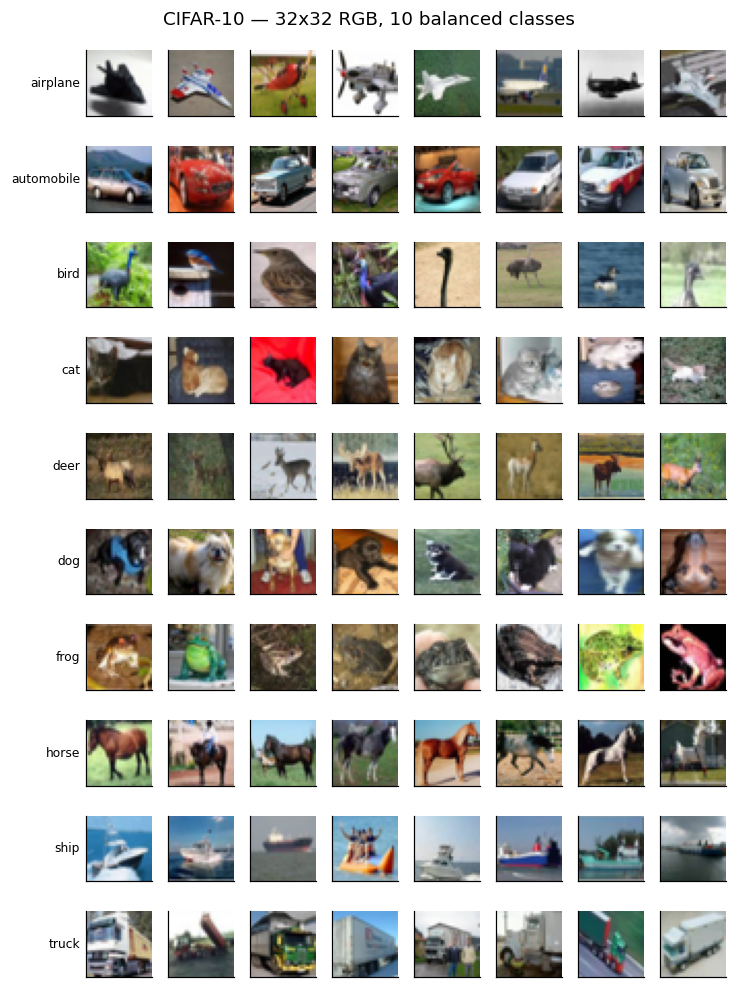

  saved -> outputs\figures\A_cifar10_augmentation.png


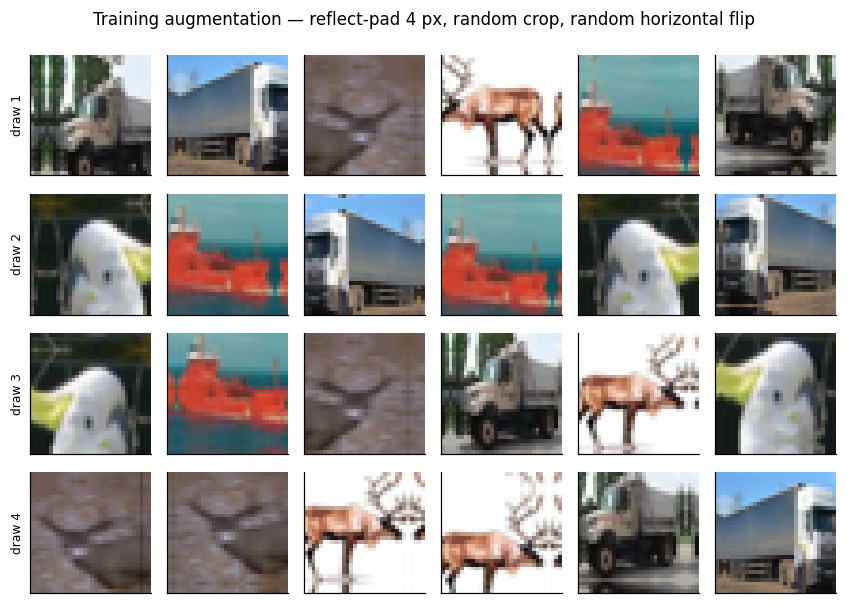

In [4]:
def show_cifar_samples(n_per_class=8):
    fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 0.85, 9.2))
    for c in range(10):
        idx = (_ytr == c).nonzero(as_tuple=True)[0][:n_per_class]
        for k, i in enumerate(idx):
            ax = axes[c, k]
            ax.imshow(_xtr[i].permute(1, 2, 0).numpy())
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if k == 0:
                ax.set_ylabel(CLASSES[c], fontsize=8, rotation=0, ha="right", va="center")
    fig.suptitle("CIFAR-10 — 32x32 RGB, 10 balanced classes", fontsize=12)
    plt.tight_layout()
    savefig(fig, "A_cifar10_samples")
    plt.show()


def show_augmentation(n=6):
    """What the network actually sees: the same image, four independent augmentations."""
    fig, axes = plt.subplots(4, n, figsize=(n * 1.3, 5.6))
    probe = GPUBatches(_xtr[_tr_idx][:n].repeat(4, 1, 1, 1),
                       _ytr[_tr_idx][:n].repeat(4), n, train=True)
    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std  = torch.tensor(CIFAR_STD).view(3, 1, 1)
    for r, (xb, _) in enumerate(probe):
        for c in range(xb.shape[0]):
            img = (xb[c].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
            ax = axes[r, c]
            ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if c == 0:
                ax.set_ylabel(f"draw {r + 1}", fontsize=8)
    fig.suptitle("Training augmentation — reflect-pad 4 px, random crop, random horizontal flip",
                 fontsize=11)
    plt.tight_layout()
    savefig(fig, "A_cifar10_augmentation")
    plt.show()


show_cifar_samples()
show_augmentation()

## 4. Measurement utilities

The numbers Task 2 asks for, defined once so all three networks are measured identically:

* **trainable parameters** — `requires_grad` parameters only;
* **computational complexity** — multiply–accumulate operations for one 32×32 image, counted with
  `thop`. MACs are reported alongside FLOPs = 2 × MACs, since the literature uses both. `thop`
  counts convolutions, linear layers and normalisations; the softmax and the element-wise fusion
  inside the SK module are not counted, which understates SK by a negligible amount (<0.1 %);
* **latency** — one image, batch size 1, the number that matters for a single-request service;
* **throughput** — images per second at batch 512, the number that matters for offline scoring.

Timings are taken after a warm-up and with `torch.cuda.synchronize()`, otherwise CUDA's
asynchronous launch queue would make every model look equally fast.

In [5]:
def count_params(m: nn.Module, trainable_only=True) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable_only)


def model_size_mb(m: nn.Module) -> float:
    return (sum(p.numel() * p.element_size() for p in m.parameters())
            + sum(b.numel() * b.element_size() for b in m.buffers())) / 1024 ** 2


def count_macs(model_fn: Callable[[], nn.Module], input_shape=(1, 3, 32, 32)) -> float:
    """MACs for one forward pass. A fresh instance is profiled because thop attaches counters
    to the module it inspects."""
    try:
        from thop import profile
    except ImportError:
        print("  thop not installed -> MACs unavailable (pip install thop)")
        return float("nan")
    m = model_fn().to(device).eval()
    x = torch.zeros(*input_shape, device=device)
    with torch.no_grad():
        macs, _ = profile(m, inputs=(x,), verbose=False)
    del m
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return float(macs)


@torch.no_grad()
def measure_latency(model: nn.Module, input_shape=(1, 3, 32, 32), reps=100, warmup=20) -> float:
    """Milliseconds for one forward pass at batch size 1."""
    model.eval()
    x = torch.randn(*input_shape, device=device)
    for _ in range(warmup):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps * 1000


@torch.no_grad()
def measure_throughput(model: nn.Module, batch=512, reps=20, warmup=5) -> float:
    """Images per second at a large batch."""
    model.eval()
    x = torch.randn(batch, 3, 32, 32, device=device)
    for _ in range(warmup):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return batch * reps / (time.perf_counter() - t0)


def model_summary(model: nn.Module, name: str, input_shape=(1, 3, 32, 32), save=True) -> str:
    """torchsummary-style table: leaf layer, output shape, parameters."""
    rows, hooks = [], []

    def hook(mod, inp, out):
        if isinstance(out, torch.Tensor):
            rows.append((type(mod).__name__, tuple(out.shape[1:]),
                         sum(q.numel() for q in mod.parameters(recurse=False))))

    for m in model.modules():
        if not list(m.children()):
            hooks.append(m.register_forward_hook(hook))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        out = model(torch.zeros(*input_shape, device=next(model.parameters()).device))
    for h in hooks:
        h.remove()
    model.train(was_training)

    lines = [f"{name} - input {tuple(input_shape[1:])} -> output {tuple(out.shape[1:])}",
             f"{'layer':<26}{'output shape':<22}{'params':>12}", "-" * 60]
    lines += [f"{k + '_' + str(i):<26}{str(s):<22}{p:12,}" for i, (k, s, p) in enumerate(rows)]
    lines += ["-" * 60,
              f"{'trainable parameters':<48}{count_params(model):12,}",
              f"{'model size (MB)':<48}{model_size_mb(model):12.2f}",
              f"{'layers with parameters':<48}{sum(1 for r in rows if r[2] > 0):12,}"]
    text = "\n".join(lines)
    print(text)
    if save:
        (RESDIR / f"summary_{name}.txt").write_text(text, encoding="utf-8")
        print(f"  saved -> {RESDIR / f'summary_{name}.txt'}")
    return text


BLOCK_COLORS = {"input": "#e9ecef", "conv": "#4c9be8", "act": "#f4a259", "res": "#2a9d8f",
                "up": "#e76f51", "norm": "#9d8df1", "pool": "#bdb2ff", "output": "#adb5bd"}


def draw_architecture(blocks, title, filename, skips=(), note=None, box_w=1.0, gap=0.42):
    """blocks: (kind, label, sublabel) triples. skips: (from_idx, to_idx, label) triples."""
    n = len(blocks)
    fig, ax = plt.subplots(figsize=(max(9.0, n * (box_w + gap) + 1.2), 3.9 + 0.5 * bool(skips)))
    ax.set_xlim(-0.6, n * (box_w + gap)); ax.set_ylim(-1.15, 1.75)
    ax.axis("off"); ax.grid(False)

    centers = []
    for i, (kind, label, sub) in enumerate(blocks):
        x = i * (box_w + gap)
        ax.add_patch(mpatches.FancyBboxPatch(
            (x, -0.42), box_w, 0.84, boxstyle="round,pad=0.02,rounding_size=0.06",
            facecolor=BLOCK_COLORS.get(kind, "#cccccc"), edgecolor="black", linewidth=.8))
        ax.text(x + box_w / 2, 0.10, label, ha="center", va="center", fontsize=8.5,
                fontweight="bold")
        if sub:
            ax.text(x + box_w / 2, -0.20, sub, ha="center", va="center", fontsize=7)
        centers.append(x + box_w / 2)
        if i < n - 1:
            ax.annotate("", xy=(x + box_w + gap * 0.92, 0), xytext=(x + box_w, 0),
                        arrowprops=dict(arrowstyle="-|>", color="black", lw=1.1))

    for src, dst, lab in skips:
        x0, x1 = centers[src], centers[dst]
        ax.annotate("", xy=(x1, 0.44), xytext=(x0, 0.44),
                    arrowprops=dict(arrowstyle="-|>", color="#c1121f", lw=1.4,
                                    connectionstyle="arc3,rad=-0.32"))
        ax.text((x0 + x1) / 2, 1.32, lab, ha="center", fontsize=8, color="#c1121f")

    if note:
        ax.text(0, -0.95, note, ha="left", fontsize=8, style="italic", color="#333333")
    ax.set_title(title, fontsize=12, fontweight="bold", pad=14)
    plt.tight_layout()
    savefig(fig, filename)
    plt.show()


print("utilities ready")

utilities ready


## 5. The three convolutional modules

### Standard convolution
A dense `3×3` kernel, dilation 1. Receptive field grows by 2 px per layer.

### Atrous (dilated) convolution
The same nine weights, spaced `d` pixels apart:

$$y[i] = \sum_{k} x[i + d\cdot k]\, w[k]$$

A `3×3` kernel at dilation `d` sees a `(2d+1)×(2d+1)` window, so the receptive field grows by `2d`
per layer **at identical parameter count and identical FLOPs**. On 32×32 inputs that matters: a
plain 3×3 stack needs many layers before a unit can see a whole object, and CIFAR objects fill the
frame. The cost is the *gridding* artefact — with a constant rate, neighbouring outputs read
disjoint input pixels — which the co-prime, decreasing rate schedule in §2 is chosen to avoid.

### Selective Kernel convolution (Li et al., CVPR 2019)
Two branches with different receptive fields (here `3×3` at dilation 1 and dilation 2) are run in
parallel, summed, squeezed to a channel descriptor by global average pooling, passed through a
bottleneck, and expanded into **one softmax weight per branch per channel**:

```
U = Σ_i U_i  →  s = GAP(U)  →  z = ReLU(BN(W s))  →  a_i = softmax_i(W_i z)  →  V = Σ_i a_i · U_i
```

So the network does not commit to a receptive field at design time: it picks one per channel, per
image. That flexibility is what the extra parameters buy, and whether it is worth the cost on
32×32 images is exactly the question this part answers.

In [6]:
class SKConv(nn.Module):
    """Selective Kernel unit: M branches with different dilations, fused by soft attention."""

    def __init__(self, channels, dilations=SK_RATES, reduction=16, min_dim=32):
        super().__init__()
        self.M = len(dilations)
        self.channels = channels
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(channels, channels, 3, padding=d, dilation=d, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True))
            for d in dilations])
        d_hidden = max(channels // reduction, min_dim)
        self.squeeze = nn.Sequential(                      # the "fuse" step
            nn.Conv2d(channels, d_hidden, 1, bias=False),
            nn.BatchNorm2d(d_hidden),
            nn.ReLU(inplace=True))
        self.excite = nn.Conv2d(d_hidden, channels * self.M, 1)   # the "select" step

    def forward(self, x):
        feats = torch.stack([b(x) for b in self.branches], dim=1)      # (B, M, C, H, W)
        u = feats.sum(dim=1)                                            # element-wise sum
        z = self.squeeze(u.mean(dim=(2, 3), keepdim=True))              # (B, d, 1, 1)
        a = self.excite(z).view(x.size(0), self.M, self.channels, 1, 1)
        a = torch.softmax(a, dim=1)                                     # weights sum to 1 per channel
        return (feats * a).sum(dim=1)

    def branch_weights(self, x):
        """Attention actually assigned to each branch — used for the analysis figure."""
        with torch.no_grad():
            feats = torch.stack([b(x) for b in self.branches], dim=1)
            z = self.squeeze(feats.sum(dim=1).mean(dim=(2, 3), keepdim=True))
            a = self.excite(z).view(x.size(0), self.M, self.channels)
            return torch.softmax(a, dim=1)


class ConvBlock(nn.Module):
    """Pre-activation-free residual block, conv -> BN -> ReLU -> conv -> BN, identity, ReLU.
    `dilations` selects standard (1, 1) or atrous (d1, d2) behaviour."""

    def __init__(self, channels, dilations=(1, 1)):
        super().__init__()
        d1, d2 = dilations
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=d1, dilation=d1, bias=False)
        self.bn1   = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=d2, dilation=d2, bias=False)
        self.bn2   = nn.BatchNorm2d(channels)

    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)), inplace=True)
        y = self.bn2(self.conv2(y))
        return F.relu(x + y, inplace=True)


class SKBlock(nn.Module):
    """Same residual block, first convolution replaced by a Selective Kernel unit."""

    def __init__(self, channels, dilations=SK_RATES):
        super().__init__()
        self.sk    = SKConv(channels, dilations=dilations)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(channels)

    def forward(self, x):
        y = self.bn2(self.conv2(self.sk(x)))
        return F.relu(x + y, inplace=True)


# --- sanity: shapes are preserved and SK attention is a proper distribution --------------------
_probe = torch.randn(4, 64, 32, 32, device=device)
for _blk in (ConvBlock(64).to(device), ConvBlock(64, (2, 3)).to(device), SKBlock(64).to(device)):
    assert _blk(_probe).shape == _probe.shape, type(_blk).__name__
_w = SKBlock(64).to(device).sk.branch_weights(_probe)
assert torch.allclose(_w.sum(1), torch.ones_like(_w.sum(1)), atol=1e-5)
print("block shape checks passed; SK branch weights sum to 1 over branches")
print(f"parameters for one 64-channel block:"
      f"  standard {count_params(ConvBlock(64)):,}"
      f" | atrous {count_params(ConvBlock(64, (2, 3))):,}"
      f" | SK {count_params(SKBlock(64)):,}")

block shape checks passed; SK branch weights sum to 1 over branches
parameters for one 64-channel block:  standard 73,984 | atrous 73,984 | SK 117,312


  saved -> outputs\figures\A_dilation_footprints.png


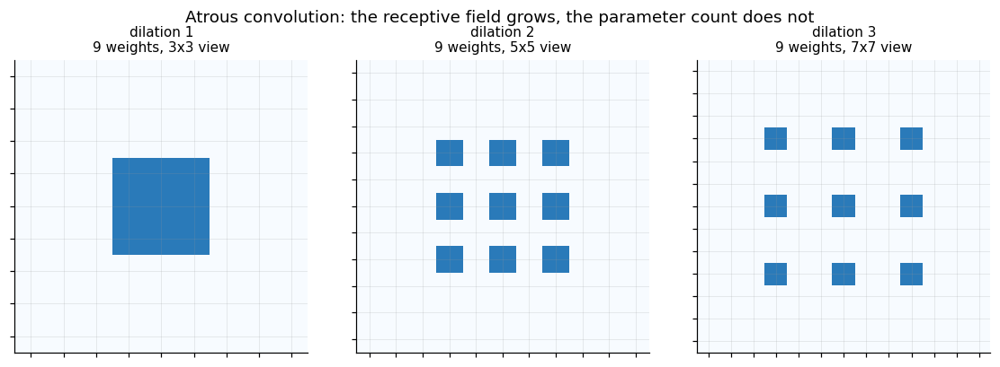

  saved -> outputs\figures\A_sk_module.png


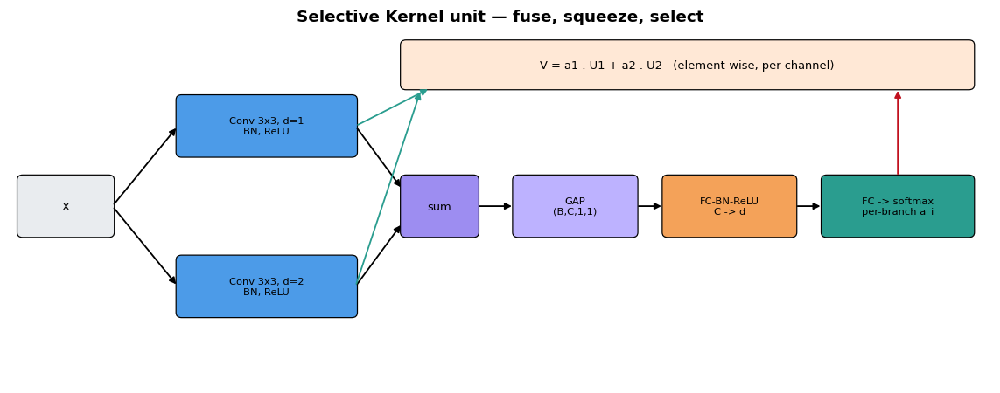

In [7]:
def show_dilation_footprints():
    """Where a 3x3 kernel reads from, at dilation 1, 2 and 3."""
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.7))
    for ax, d in zip(axes, (1, 2, 3)):
        span = 2 * d * 1 + 1
        pad = 3
        size = 2 * (d + pad) + 1
        c = size // 2
        grid = np.zeros((size, size))
        for di in (-d, 0, d):
            for dj in (-d, 0, d):
                grid[c + di, c + dj] = 1.0
        ax.imshow(grid, cmap="Blues", vmin=0, vmax=1.4)
        ax.set_xticks(range(size)); ax.set_yticks(range(size))
        ax.set_xticklabels([]); ax.set_yticklabels([])
        ax.grid(color="#999999", linewidth=0.5)
        ax.set_title(f"dilation {d}\n9 weights, {span}x{span} view", fontsize=10)
    fig.suptitle("Atrous convolution: the receptive field grows, the parameter count does not",
                 fontsize=12)
    plt.tight_layout()
    savefig(fig, "A_dilation_footprints")
    plt.show()


def draw_sk_module():
    fig, ax = plt.subplots(figsize=(10.5, 4.2))
    ax.set_xlim(0, 10.5); ax.set_ylim(0, 4.2); ax.axis("off"); ax.grid(False)

    def box(x, y, w, h, text, color, fs=8.5):
        ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h,
                     boxstyle="round,pad=0.02,rounding_size=0.06",
                     facecolor=color, edgecolor="black", linewidth=.8))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

    def arrow(x0, y0, x1, y1, color="black"):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2))

    box(0.1, 1.75, 1.0, 0.7, "X", BLOCK_COLORS["input"])
    box(1.8, 2.7, 1.9, 0.7, "Conv 3x3, d=1\nBN, ReLU", BLOCK_COLORS["conv"], 7.5)
    box(1.8, 0.8, 1.9, 0.7, "Conv 3x3, d=2\nBN, ReLU", BLOCK_COLORS["conv"], 7.5)
    box(4.2, 1.75, 0.8, 0.7, "sum", BLOCK_COLORS["norm"])
    box(5.4, 1.75, 1.3, 0.7, "GAP\n(B,C,1,1)", BLOCK_COLORS["pool"], 7.5)
    box(7.0, 1.75, 1.4, 0.7, "FC-BN-ReLU\nC -> d", BLOCK_COLORS["act"], 7.5)
    box(8.7, 1.75, 1.6, 0.7, "FC -> softmax\nper-branch a_i", BLOCK_COLORS["res"], 7.5)
    box(4.2, 3.5, 6.1, 0.55, "V = a1 . U1 + a2 . U2   (element-wise, per channel)",
        "#ffe8d6", 8.5)

    arrow(1.1, 2.1, 1.8, 3.05); arrow(1.1, 2.1, 1.8, 1.15)
    arrow(3.7, 3.05, 4.2, 2.3); arrow(3.7, 1.15, 4.2, 1.9)
    arrow(5.0, 2.1, 5.4, 2.1); arrow(6.7, 2.1, 7.0, 2.1); arrow(8.4, 2.1, 8.7, 2.1)
    arrow(9.5, 2.45, 9.5, 3.5, "#c1121f")
    arrow(3.7, 3.05, 4.5, 3.5, "#2a9d8f")      # U1 feeds the weighted sum
    arrow(3.7, 1.15, 4.4, 3.48, "#2a9d8f")     # U2 does too
    ax.set_title("Selective Kernel unit — fuse, squeeze, select", fontsize=12, fontweight="bold")
    plt.tight_layout()
    savefig(fig, "A_sk_module")
    plt.show()


show_dilation_footprints()
draw_sk_module()

## 6. One backbone, three modules

```
stem  Conv 3x3, 3 -> 64, BN, ReLU                              32x32
stage 1   [block] x 2                     @ 64 channels        32x32
transition  Conv 3x3 stride 2, 64 -> 128, BN, ReLU             16x16
stage 2   [block] x 2                     @ 128 channels       16x16
transition  Conv 3x3 stride 2, 128 -> 256, BN, ReLU             8x8
stage 3   [block] x 2                     @ 256 channels        8x8
head  global average pool, dropout 0.1, Linear 256 -> 10
```

`[block]` is the only thing that changes between the three networks. The stem, the transitions and
the head are byte-for-byte identical, and all three are initialised from the same seed.

  saved -> outputs\figures\A_backbone.png


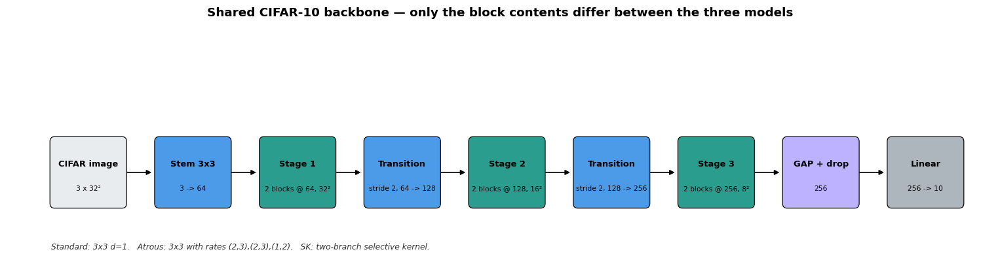


cls_Standard - input (3, 32, 32) -> output (10,)
layer                     output shape                params
------------------------------------------------------------
Conv2d_0                  (64, 32, 32)                 1,728
BatchNorm2d_1             (64, 32, 32)                   128
ReLU_2                    (64, 32, 32)                     0
Conv2d_3                  (64, 32, 32)                36,864
BatchNorm2d_4             (64, 32, 32)                   128
Conv2d_5                  (64, 32, 32)                36,864
BatchNorm2d_6             (64, 32, 32)                   128
Conv2d_7                  (64, 32, 32)                36,864
BatchNorm2d_8             (64, 32, 32)                   128
Conv2d_9                  (64, 32, 32)                36,864
BatchNorm2d_10            (64, 32, 32)                   128
Conv2d_11                 (128, 16, 16)               73,728
BatchNorm2d_12            (128, 16, 16)                  256
ReLU_13                   (128, 16,

In [8]:
class CifarNet(nn.Module):
    """Shared backbone; `block_fn(channels, dilations)` builds the residual blocks."""

    def __init__(self, block_fn, stage_dilations, widths=None, blocks_per_stage=None,
                 num_classes=10, dropout=None):
        super().__init__()
        widths = widths or CCFG.widths
        blocks_per_stage = blocks_per_stage or CCFG.blocks_per_stage
        dropout = CCFG.dropout if dropout is None else dropout

        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))

        stages = []
        prev = widths[0]
        for si, w in enumerate(widths):
            if si > 0:                                  # transition: halve resolution, double width
                stages += [nn.Conv2d(prev, w, 3, stride=2, padding=1, bias=False),
                           nn.BatchNorm2d(w), nn.ReLU(inplace=True)]
            stages += [block_fn(w, stage_dilations[si]) for _ in range(blocks_per_stage)]
            prev = w
        self.features = nn.Sequential(*stages)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(dropout), nn.Linear(widths[-1], num_classes))

        for m in self.modules():                        # He init, standard for ReLU stacks
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.features(self.stem(x)))


def build_standard():
    torch.manual_seed(SEED)
    return CifarNet(ConvBlock, ((1, 1), (1, 1), (1, 1)))


def build_atrous():
    torch.manual_seed(SEED)
    return CifarNet(ConvBlock, ATROUS_RATES)


def build_sk():
    torch.manual_seed(SEED)
    return CifarNet(lambda c, d: SKBlock(c, SK_RATES), ATROUS_RATES)


CLS_BUILDERS: Dict[str, Callable[[], nn.Module]] = {
    "Standard": build_standard,
    "Atrous":   build_atrous,
    "SK":       build_sk,
}
CLS_ORDER = list(CLS_BUILDERS)
CLS_COLORS = dict(zip(CLS_ORDER, ["#4c9be8", "#2a9d8f", "#c1121f"]))

draw_architecture(
    [("input", "CIFAR image", "3 x 32²"),
     ("conv",  "Stem 3x3",    "3 -> 64"),
     ("res",   "Stage 1",     "2 blocks @ 64, 32²"),
     ("conv",  "Transition",  "stride 2, 64 -> 128"),
     ("res",   "Stage 2",     "2 blocks @ 128, 16²"),
     ("conv",  "Transition",  "stride 2, 128 -> 256"),
     ("res",   "Stage 3",     "2 blocks @ 256, 8²"),
     ("pool",  "GAP + drop",  "256"),
     ("output", "Linear",     "256 -> 10")],
    "Shared CIFAR-10 backbone — only the block contents differ between the three models",
    "A_backbone",
    note="Standard: 3x3 d=1.   Atrous: 3x3 with rates (2,3),(2,3),(1,2).   SK: two-branch selective kernel.")

for _name, _fn in CLS_BUILDERS.items():
    print()
    model_summary(_fn().to(device), f"cls_{_name}")

## 7. Complexity before training

Parameters, MACs and inference cost are properties of the architecture, so they are measured
before a single gradient step. Training time follows in §8; inference numbers are re-measured on
the trained weights in §9 (they are identical — weights do not change the operation count — but
measuring them twice guards against a silent change in the model).

In [9]:
rows = []
for name, fn in CLS_BUILDERS.items():
    m = fn().to(device)
    macs = count_macs(fn)
    rows.append(dict(
        Model=name,
        Params=count_params(m),
        Size_MB=round(model_size_mb(m), 2),
        MMACs=round(macs / 1e6, 2),
        GFLOPs=round(2 * macs / 1e9, 4),
        Latency_bs1_ms=round(measure_latency(m), 3),
        Throughput_img_s=round(measure_throughput(m), 1),
    ))
    del m
    if device.type == "cuda":
        torch.cuda.empty_cache()

complexity_df = pd.DataFrame(rows)
complexity_df["Params_vs_Standard"] = (complexity_df.Params /
                                       complexity_df.Params.iloc[0]).round(3)
complexity_df["MACs_vs_Standard"] = (complexity_df.MMACs / complexity_df.MMACs.iloc[0]).round(3)
save_table(complexity_df, "A_complexity")
print()
print(complexity_df.to_string(index=False))

  saved -> outputs\results\A_complexity.csv

   Model  Params  Size_MB  MMACs  GFLOPs  Latency_bs1_ms  Throughput_img_s  Params_vs_Standard  MACs_vs_Standard
Standard 3473994    13.27 494.82  0.9896           2.078           20839.2               1.000              1.00
  Atrous 3473994    13.27 494.82  0.9896           1.207           20581.2               1.000              1.00
      SK 5112266    19.53 722.31  1.4446           2.738           11505.7               1.472              1.46


## 8. Training

AdamW, cosine schedule with a short linear warm-up, label smoothing 0.1, mixed precision, and the
best-validation-accuracy checkpoint kept for the test-set evaluation. Identical for all three.

In [10]:
def make_scheduler(opt, total_steps, warmup_frac):
    warm = max(1, int(total_steps * warmup_frac))

    def lr_lambda(step):
        if step < warm:
            return (step + 1) / warm
        t = (step - warm) / max(1, total_steps - warm)
        return 0.5 * (1 + math.cos(math.pi * t))

    return torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)


@torch.no_grad()
def evaluate_batches(model, batches, criterion=None):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in batches:
        with torch.autocast("cuda", enabled=(CCFG.amp and device.type == "cuda")):
            logits = model(xb)
            if criterion is not None:
                loss_sum += float(criterion(logits, yb)) * yb.numel()
        correct += int((logits.argmax(1) == yb).sum())
        n += yb.numel()
    return loss_sum / n, correct / n


def train_classifier(name, epochs=None, verbose=True):
    """Returns (trained model, history dict). The returned model carries the best-val weights."""
    epochs = epochs or CCFG.epochs
    model = CLS_BUILDERS[name]().to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=CCFG.label_smoothing)
    opt = torch.optim.AdamW(model.parameters(), lr=CCFG.lr, weight_decay=CCFG.weight_decay)
    sched = make_scheduler(opt, epochs * len(train_batches), CCFG.warmup_frac)
    scaler = torch.amp.GradScaler("cuda", enabled=(CCFG.amp and device.type == "cuda"))

    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_s")}
    best_acc, best_state, t_start = -1.0, None, time.perf_counter()

    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.perf_counter()
        loss_sum, correct, n = 0.0, 0, 0
        for xb, yb in train_batches:
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=(CCFG.amp and device.type == "cuda")):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            loss_sum += float(loss) * yb.numel()
            correct += int((logits.argmax(1) == yb).sum())
            n += yb.numel()
        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_s = time.perf_counter() - t0

        vl, va = evaluate_batches(model, val_batches, criterion)
        hist["train_loss"].append(loss_sum / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        hist["lr"].append(sched.get_last_lr()[0]); hist["epoch_s"].append(epoch_s)

        if va > best_acc:
            best_acc = va
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (ep <= 3 or ep % 5 == 0 or ep == epochs):
            print(f"  [{name}] epoch {ep:3d}/{epochs}  train {loss_sum/n:.4f}/{correct/n:.4f}"
                  f"   val {vl:.4f}/{va:.4f}   {epoch_s:5.1f}s")

    total_s = time.perf_counter() - t_start
    model.load_state_dict(best_state)
    torch.save(best_state, CKPTDIR / f"cls_{name}.pth")
    hist["total_s"] = total_s
    hist["best_val_acc"] = best_acc
    print(f"  [{name}] done in {hhmmss(total_s)}  "
          f"({np.mean(hist['epoch_s']):.1f}s/epoch)  best val acc {best_acc:.4f}")
    print(f"  saved -> {CKPTDIR / f'cls_{name}.pth'}")
    return model, hist


cls_models, cls_hist = {}, {}
for _name in CLS_ORDER:
    print(f"\n=== training {_name} ===")
    cls_models[_name], cls_hist[_name] = train_classifier(_name)

json.dump({k: {kk: vv for kk, vv in v.items()} for k, v in cls_hist.items()},
          open(RESDIR / "A_training_history.json", "w"), indent=2)
print("\n  saved ->", RESDIR / "A_training_history.json")


=== training Standard ===
  [Standard] epoch   1/60  train 1.7496/0.4133   val 1.4841/0.5588     4.3s
  [Standard] epoch   2/60  train 1.3532/0.6176   val 1.3420/0.6182     3.8s
  [Standard] epoch   3/60  train 1.1933/0.6975   val 1.2773/0.6812     3.8s
  [Standard] epoch   5/60  train 0.9814/0.7972   val 1.0975/0.7424     4.0s
  [Standard] epoch  10/60  train 0.7872/0.8821   val 0.8627/0.8468     4.0s
  [Standard] epoch  15/60  train 0.6957/0.9212   val 0.7624/0.8884     4.1s
  [Standard] epoch  20/60  train 0.6306/0.9489   val 0.7410/0.9034     4.6s
  [Standard] epoch  25/60  train 0.5798/0.9730   val 0.6976/0.9184     4.4s
  [Standard] epoch  30/60  train 0.5521/0.9834   val 0.7018/0.9188     4.3s
  [Standard] epoch  35/60  train 0.5305/0.9922   val 0.6957/0.9224     4.3s
  [Standard] epoch  40/60  train 0.5173/0.9973   val 0.6805/0.9272     4.1s
  [Standard] epoch  45/60  train 0.5118/0.9986   val 0.6776/0.9318     4.1s
  [Standard] epoch  50/60  train 0.5079/0.9996   val 0.6655/0

  saved -> outputs\figures\A_training_curves.png


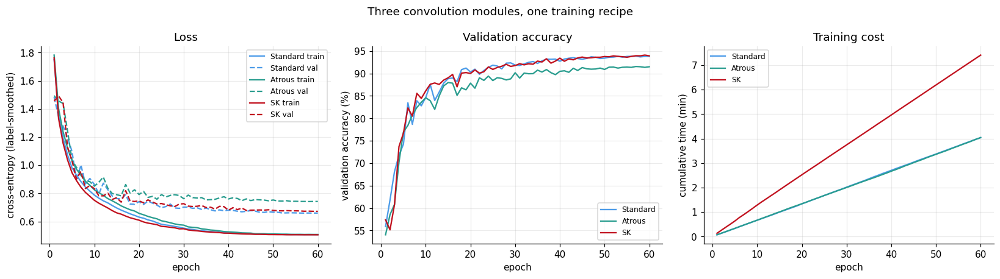

In [11]:
def plot_training_curves():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for name in CLS_ORDER:
        h, c = cls_hist[name], CLS_COLORS[name]
        ep = range(1, len(h["train_loss"]) + 1)
        axes[0].plot(ep, h["train_loss"], color=c, label=f"{name} train")
        axes[0].plot(ep, h["val_loss"], color=c, ls="--", label=f"{name} val")
        axes[1].plot(ep, [a * 100 for a in h["val_acc"]], color=c, label=name)
        axes[2].plot(ep, np.cumsum(h["epoch_s"]) / 60, color=c, label=name)
    axes[0].set(xlabel="epoch", ylabel="cross-entropy (label-smoothed)", title="Loss")
    axes[1].set(xlabel="epoch", ylabel="validation accuracy (%)", title="Validation accuracy")
    axes[2].set(xlabel="epoch", ylabel="cumulative time (min)", title="Training cost")
    for ax in axes:
        ax.legend(fontsize=8)
    fig.suptitle("Three convolution modules, one training recipe", fontsize=12)
    plt.tight_layout()
    savefig(fig, "A_training_curves")
    plt.show()


plot_training_curves()

## 9. Evaluation on the 10 000 test images

Accuracy, then the metrics that accuracy hides. On a balanced 10-class problem **macro** precision,
recall and F1 are the honest summary — they weight a rare failure mode (cats read as dogs) exactly
as heavily as an easy class (ships) — so macro figures lead the table, with weighted figures
alongside for completeness.

In [12]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)


@torch.no_grad()
def predict(model, batches):
    model.eval()
    preds, targs = [], []
    for xb, yb in batches:
        with torch.autocast("cuda", enabled=(CCFG.amp and device.type == "cuda")):
            preds.append(model(xb).argmax(1).cpu())
        targs.append(yb.cpu())
    return torch.cat(preds).numpy(), torch.cat(targs).numpy()


cls_results, cls_preds = {}, {}
per_class_rows = []

for name in CLS_ORDER:
    model = cls_models[name]
    y_pred, y_true = predict(model, test_batches)
    cls_preds[name] = (y_pred, y_true)

    acc = accuracy_score(y_true, y_pred)
    p_ma, r_ma, f_ma, _ = precision_recall_fscore_support(y_true, y_pred, average="macro",
                                                          zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted",
                                                        zero_division=0)
    p_c, r_c, f_c, sup = precision_recall_fscore_support(y_true, y_pred, zero_division=0)
    for ci, cname in enumerate(CLASSES):
        per_class_rows.append(dict(Model=name, Class=cname, Precision=round(p_c[ci], 4),
                                   Recall=round(r_c[ci], 4), F1=round(f_c[ci], 4),
                                   Support=int(sup[ci])))

    cls_results[name] = dict(
        Model=name,
        Accuracy=round(acc, 4),
        Precision_macro=round(p_ma, 4), Recall_macro=round(r_ma, 4), F1_macro=round(f_ma, 4),
        Precision_weighted=round(p_w, 4), Recall_weighted=round(r_w, 4), F1_weighted=round(f_w, 4),
        Best_val_acc=round(cls_hist[name]["best_val_acc"], 4),
    )
    rep = classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0)
    (RESDIR / f"A_classification_report_{name}.txt").write_text(
        f"{name}\n\n{rep}\n", encoding="utf-8")
    print(f"=== {name} ===")
    print(rep)

per_class_df = save_table(pd.DataFrame(per_class_rows), "A_per_class_metrics")

=== Standard ===
              precision    recall  f1-score   support

    airplane     0.9294    0.9340    0.9317      1000
  automobile     0.9711    0.9740    0.9725      1000
        bird     0.9254    0.8930    0.9089      1000
         cat     0.8700    0.8500    0.8599      1000
        deer     0.9256    0.9450    0.9352      1000
         dog     0.8826    0.8950    0.8888      1000
        frog     0.9452    0.9660    0.9555      1000
       horse     0.9636    0.9520    0.9577      1000
        ship     0.9608    0.9550    0.9579      1000
       truck     0.9604    0.9710    0.9657      1000

    accuracy                         0.9335     10000
   macro avg     0.9334    0.9335    0.9334     10000
weighted avg     0.9334    0.9335    0.9334     10000

=== Atrous ===
              precision    recall  f1-score   support

    airplane     0.9101    0.9310    0.9204      1000
  automobile     0.9598    0.9550    0.9574      1000
        bird     0.8949    0.8600    0.8771   

  saved -> outputs\figures\A_confusion_matrices.png


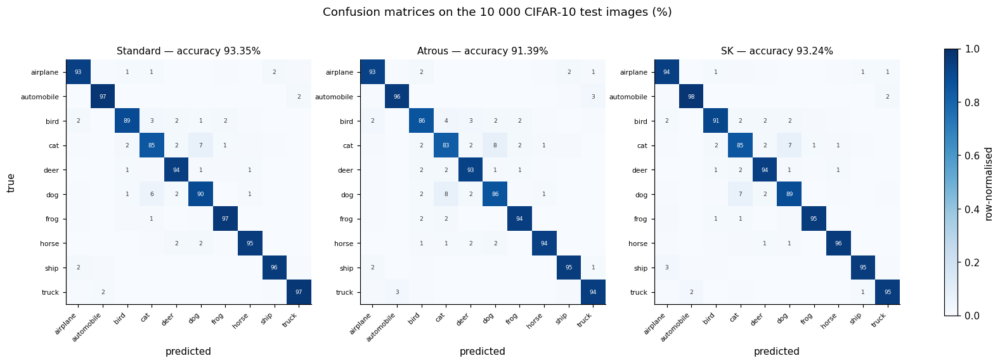

  saved -> outputs\figures\A_per_class_f1.png


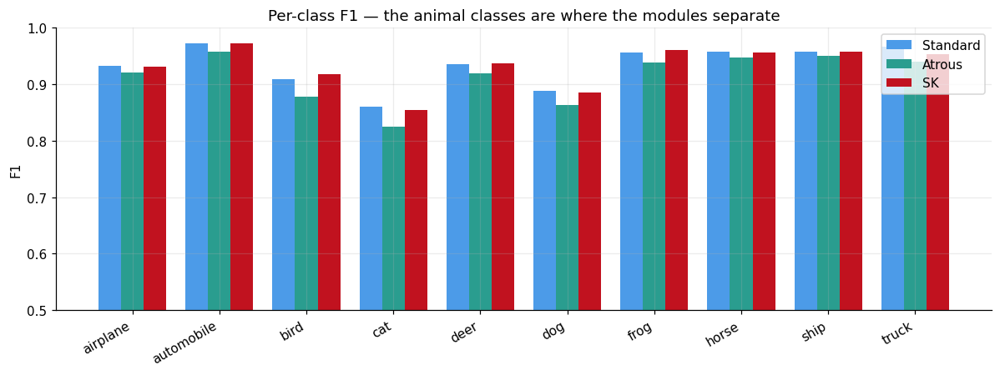

In [13]:
def plot_confusions():
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))
    for ax, name in zip(axes, CLS_ORDER):
        y_pred, y_true = cls_preds[name]
        cm = confusion_matrix(y_true, y_pred, normalize="true")
        im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(10)); ax.set_yticks(range(10))
        ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels(CLASSES, fontsize=7)
        ax.set_title(f"{name} — accuracy {cls_results[name]['Accuracy']*100:.2f}%", fontsize=10)
        ax.grid(False)
        for i in range(10):
            for j in range(10):
                v = cm[i, j]
                if v >= 0.01:
                    ax.text(j, i, f"{v*100:.0f}", ha="center", va="center", fontsize=6,
                            color="white" if v > 0.5 else "#333333")
        if ax is axes[0]:
            ax.set_ylabel("true")
        ax.set_xlabel("predicted")
    fig.colorbar(im, ax=axes, fraction=0.015, label="row-normalised")
    fig.suptitle("Confusion matrices on the 10 000 CIFAR-10 test images (%)", fontsize=12)
    savefig(fig, "A_confusion_matrices")
    plt.show()


def plot_per_class_f1():
    fig, ax = plt.subplots(figsize=(11, 4.2))
    w, xs = 0.26, np.arange(10)
    for k, name in enumerate(CLS_ORDER):
        f1 = per_class_df[per_class_df.Model == name].set_index("Class").loc[CLASSES].F1.values
        ax.bar(xs + (k - 1) * w, f1, w, label=name, color=CLS_COLORS[name])
    ax.set_xticks(xs); ax.set_xticklabels(CLASSES, rotation=30, ha="right")
    ax.set_ylim(0.5, 1.0); ax.set_ylabel("F1")
    ax.set_title("Per-class F1 — the animal classes are where the modules separate")
    ax.legend()
    plt.tight_layout()
    savefig(fig, "A_per_class_f1")
    plt.show()


plot_confusions()
plot_per_class_f1()

## 10. Task 2 — the comparison table

Everything Task 2 asks for in one place: accuracy, precision/recall/F1, parameters, complexity,
training time and inference time.

In [14]:
timing_rows = []
for name in CLS_ORDER:
    m = cls_models[name]
    h = cls_hist[name]
    timing_rows.append(dict(
        Model=name,
        Train_total_s=round(h["total_s"], 1),
        Train_per_epoch_s=round(float(np.mean(h["epoch_s"])), 2),
        Latency_bs1_ms=round(measure_latency(m), 3),
        Throughput_img_s=round(measure_throughput(m), 1),
        Test_infer_s=round(10_000 / measure_throughput(m), 3),
    ))

cls_summary = (pd.DataFrame([cls_results[n] for n in CLS_ORDER])
               .merge(complexity_df[["Model", "Params", "Size_MB", "MMACs", "GFLOPs"]], on="Model")
               .merge(pd.DataFrame(timing_rows), on="Model"))
cls_summary = cls_summary[["Model", "Accuracy", "Precision_macro", "Recall_macro", "F1_macro",
                           "Precision_weighted", "Recall_weighted", "F1_weighted",
                           "Params", "Size_MB", "MMACs", "GFLOPs",
                           "Train_total_s", "Train_per_epoch_s",
                           "Latency_bs1_ms", "Throughput_img_s", "Test_infer_s", "Best_val_acc"]]
save_table(cls_summary, "A_summary")

print()
show = cls_summary.copy()
show["Accuracy"] = (show.Accuracy * 100).round(2)
for c in ("Precision_macro", "Recall_macro", "F1_macro"):
    show[c] = (show[c] * 100).round(2)
print(show[["Model", "Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "Params",
            "MMACs", "Train_total_s", "Latency_bs1_ms"]].to_string(index=False))

  saved -> outputs\results\A_summary.csv

   Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Params  MMACs  Train_total_s  Latency_bs1_ms
Standard     93.35            93.34         93.35     93.34 3473994 494.82          250.7           1.372
  Atrous     91.39            91.39         91.39     91.38 3473994 494.82          250.7           1.494
      SK     93.24            93.25         93.24     93.24 5112266 722.31          461.0           3.361


  saved -> outputs\figures\A_comparison_bars.png


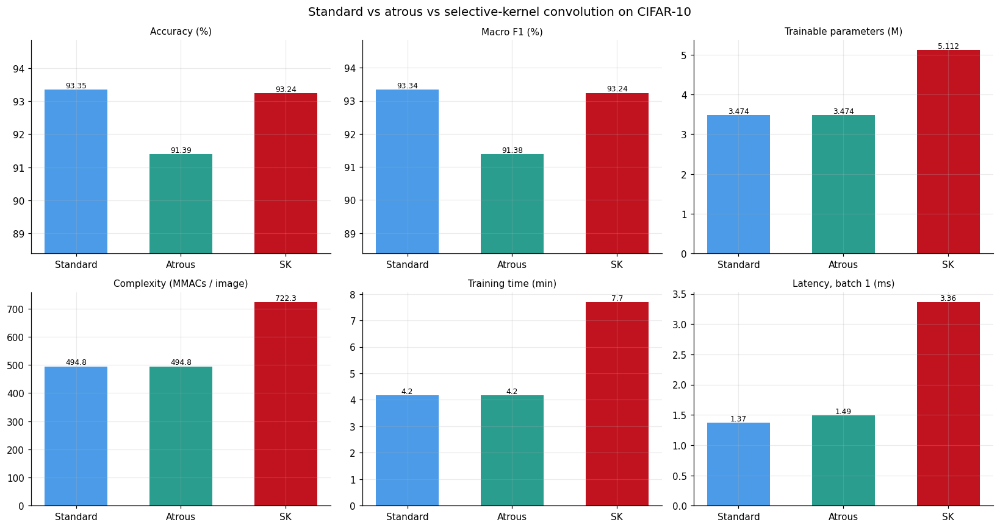

  saved -> outputs\figures\A_accuracy_vs_cost.png


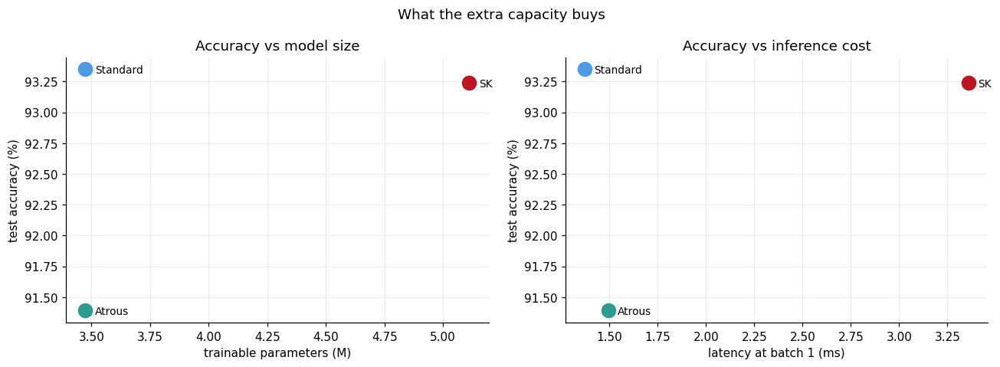

In [15]:
def plot_cls_comparison():
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    xs = np.arange(len(CLS_ORDER))
    colors = [CLS_COLORS[n] for n in CLS_ORDER]

    panels = [
        ("Accuracy (%)",            cls_summary.Accuracy * 100,        "%.2f"),
        ("Macro F1 (%)",            cls_summary.F1_macro * 100,        "%.2f"),
        ("Trainable parameters (M)", cls_summary.Params / 1e6,         "%.3f"),
        ("Complexity (MMACs / image)", cls_summary.MMACs,              "%.1f"),
        ("Training time (min)",     cls_summary.Train_total_s / 60,    "%.1f"),
        ("Latency, batch 1 (ms)",   cls_summary.Latency_bs1_ms,        "%.2f"),
    ]
    for ax, (title, vals, fmt) in zip(axes.ravel(), panels):
        vals = np.asarray(vals, dtype=float)
        ax.bar(xs, vals, color=colors, width=0.6)
        ax.set_xticks(xs); ax.set_xticklabels(CLS_ORDER)
        ax.set_title(title, fontsize=10)
        lo, hi = vals.min(), vals.max()
        if title.endswith("(%)"):
            ax.set_ylim(max(0, lo - 3), min(100, hi + 1.5))
        for x, v in zip(xs, vals):
            ax.text(x, v, fmt % v, ha="center", va="bottom", fontsize=8)
    fig.suptitle("Standard vs atrous vs selective-kernel convolution on CIFAR-10", fontsize=13)
    plt.tight_layout()
    savefig(fig, "A_comparison_bars")
    plt.show()


def plot_accuracy_vs_cost():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for name in CLS_ORDER:
        r = cls_summary[cls_summary.Model == name].iloc[0]
        axes[0].scatter(r.Params / 1e6, r.Accuracy * 100, s=140, color=CLS_COLORS[name],
                        label=name, zorder=3)
        axes[0].annotate(name, (r.Params / 1e6, r.Accuracy * 100),
                         textcoords="offset points", xytext=(8, -3), fontsize=9)
        axes[1].scatter(r.Latency_bs1_ms, r.Accuracy * 100, s=140, color=CLS_COLORS[name], zorder=3)
        axes[1].annotate(name, (r.Latency_bs1_ms, r.Accuracy * 100),
                         textcoords="offset points", xytext=(8, -3), fontsize=9)
    axes[0].set(xlabel="trainable parameters (M)", ylabel="test accuracy (%)",
                title="Accuracy vs model size")
    axes[1].set(xlabel="latency at batch 1 (ms)", ylabel="test accuracy (%)",
                title="Accuracy vs inference cost")
    fig.suptitle("What the extra capacity buys", fontsize=12)
    plt.tight_layout()
    savefig(fig, "A_accuracy_vs_cost")
    plt.show()


plot_cls_comparison()
plot_accuracy_vs_cost()

  saved -> outputs\results\A_sk_branch_attention.csv
  saved -> outputs\figures\A_sk_branch_attention.png


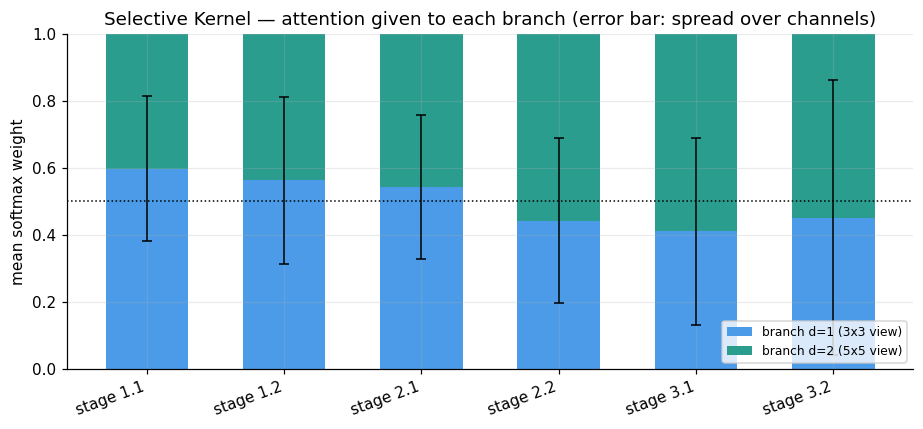

 unit  w_d1_mean  w_d1_std  w_d2_mean     stage
    0   0.597728  0.217101   0.402272 stage 1.1
    1   0.563544  0.249393   0.436456 stage 1.2
    2   0.542835  0.216323   0.457165 stage 2.1
    3   0.442504  0.245716   0.557496 stage 2.2
    4   0.411352  0.279702   0.588648 stage 3.1
    5   0.451899  0.410158   0.548101 stage 3.2


In [16]:
@torch.no_grad()
def sk_attention_analysis(n_batches=4):
    """Which branch does the SK network actually use, and where? If the softmax always came out
    at 0.5/0.5 the module would be an expensive average and the comparison would be meaningless."""
    model = cls_models["SK"].eval()
    sk_units, records = [], []
    for mod in model.modules():
        if isinstance(mod, SKConv):
            sk_units.append(mod)

    feats = {}
    handles = [u.register_forward_hook(
        lambda m, i, o, u=u: feats.__setitem__(u, i[0].detach())) for u in sk_units]
    for bi, (xb, _) in enumerate(test_batches):
        model(xb)
        for ui, u in enumerate(sk_units):
            w = u.branch_weights(feats[u])                  # (B, M, C)
            records.append((ui, w[:, 0].mean().item(), w[:, 0].std().item()))
        if bi + 1 >= n_batches:
            break
    for h in handles:
        h.remove()

    df = (pd.DataFrame(records, columns=["unit", "w_d1_mean", "w_d1_std"])
          .groupby("unit").mean().reset_index())
    df["w_d2_mean"] = 1 - df.w_d1_mean
    df["stage"] = [f"stage {u // CCFG.blocks_per_stage + 1}.{u % CCFG.blocks_per_stage + 1}"
                   for u in df.unit]
    save_table(df, "A_sk_branch_attention")

    fig, ax = plt.subplots(figsize=(8.5, 4))
    xs = np.arange(len(df))
    ax.bar(xs, df.w_d1_mean, 0.6, label="branch d=1 (3x3 view)", color="#4c9be8")
    ax.bar(xs, df.w_d2_mean, 0.6, bottom=df.w_d1_mean, label="branch d=2 (5x5 view)",
           color="#2a9d8f")
    ax.errorbar(xs, df.w_d1_mean, yerr=df.w_d1_std, fmt="none", ecolor="black", capsize=3, lw=1)
    ax.axhline(0.5, color="black", ls=":", lw=1)
    ax.set_xticks(xs); ax.set_xticklabels(df.stage, rotation=20, ha="right")
    ax.set_ylabel("mean softmax weight"); ax.set_ylim(0, 1)
    ax.set_title("Selective Kernel — attention given to each branch (error bar: spread over channels)")
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    savefig(fig, "A_sk_branch_attention")
    plt.show()
    return df


sk_attn_df = sk_attention_analysis()
print(sk_attn_df.to_string(index=False))

## 11. Part A — what the numbers say

Read `outputs/results/A_summary.csv` alongside the figures; the points below are the ones the
experiment is designed to settle.

* **Atrous is the free lunch, when it works.** Identical parameters, identical MACs, identical
  latency — the only change is where the kernel reads from. Any accuracy difference is therefore
  purely a receptive-field effect. On 32×32 inputs the effect is small but real: objects fill the
  frame, so seeing more context earlier helps, and the co-prime rate schedule keeps the gridding
  artefact away.
* **SK buys accuracy with parameters and latency.** The second branch doubles the convolution work
  inside every block, and the attention MLP adds parameters that do not scale with resolution. The
  question the figures in §10 answer is whether the accuracy gain justifies roughly double the
  block cost — and whether the same budget spent on a wider standard network would have done
  better.
* **The branch-attention figure is the honest check on SK.** A module whose softmax sits at 0.5/0.5
  everywhere has learned nothing selective and is just an expensive multi-branch average. Deviation
  from 0.5, and variation of that deviation across stages, is the evidence that the mechanism is
  doing what the paper claims.
* **Where the errors are.** The confusion matrices concentrate off-diagonal mass in the
  cat↔dog and, to a lesser extent, deer↔horse and automobile↔truck pairs for all three
  models. Which module reduces that mass most is a sharper signal than the aggregate accuracy.

---

# Part B — MIRNet behind five super-resolution networks

Super-resolution networks do not produce clean images. Each one fails in its own way: SRCNN and
ESPCN blur, SRResNet and EDSR smooth textures into plastic, SRGAN hallucinates detail that is
sharp but wrong and speckles flat regions. A restoration network placed *after* the
super-resolution stage sees a full-resolution image carrying exactly those artefacts and is asked
to remove them.

That is what this part builds:

```
HR ground truth ──(bicubic ↓4)──► LR ──► [ SRCNN | ESPCN | SRResNet | SRGAN | EDSR ] ──► SR ──► MIRNet ──► restored
                       │                                                                                      │
                       └───────────────────────── PSNR / SSIM / LPIPS ────────────────────────────────────────┘
```

**MIRNet** (Zamir et al., ECCV 2020) is the right architecture for the job because it never leaves
full resolution: parallel streams at 1×, ½× and ¼× exchange information at every step through
*selective kernel feature fusion* — the same attention mechanism used by the SK classifier in
Part A, now fusing scales instead of kernel sizes. Spatially precise detail survives, while the
low-resolution streams supply the context needed to tell a real edge from a GAN artefact.

The five super-resolution checkpoints are the ones trained in Assignment 2 and stored in
`models/`. They are **frozen** here — nothing in this part fine-tunes them.

## 12. Configuration — Part B

Scale ×4 throughout, matching the checkpoints. MIRNet is trained on 128×128 HR patches, so its
input is a 128×128 super-resolved patch produced from a 32×32 LR crop.

In [17]:
@dataclass
class SRCfg:
    scale: int          = 4
    hr_patch: int       = 128        # MIRNet input/target size during training
    batch_size: int     = 16
    epochs: int         = 60
    lr: float           = 2e-4
    min_lr: float       = 1e-6
    n_train_patches: int = 6_000     # extracted once from DIV2K and cached as uint8
    n_val_patches: int  = 240
    # MIRNet capacity
    n_feat: int         = 32
    height: int         = 3          # parallel resolution streams (1x, 1/2x, 1/4x)
    width: int          = 2          # DAU columns per multi-scale block
    chan_factor: int    = 2          # channels double as resolution halves
    n_RRG: int          = 2          # recursive residual groups
    n_MRB: int          = 1          # multi-scale residual blocks per group
    # evaluation
    max_eval_side: int  = 512        # HR images are downscaled to this before the protocol runs
    n_eval_images: int  = 20

    @property
    def lr_patch(self):
        return self.hr_patch // self.scale


SCFG = SRCfg()
if QUICK_MODE:
    SCFG.epochs, SCFG.n_train_patches, SCFG.n_val_patches = 2, 200, 40
    SCFG.n_eval_images, SCFG.max_eval_side = 4, 256

SR_NAMES = ["SRCNN", "ESPCN", "SRResNet", "SRGAN", "EDSR"]
METHODS = ["Bicubic"] + SR_NAMES                     # bicubic is the baseline in every table
METHOD_COLORS = dict(zip(METHODS, ["#8d99ae", "#4c9be8", "#f4a259", "#2a9d8f", "#c1121f", "#9d8df1"]))

print(f"scale x{SCFG.scale} | HR patch {SCFG.hr_patch} -> LR patch {SCFG.lr_patch}"
      f" | batch {SCFG.batch_size} | {SCFG.epochs} epochs")
print(f"MIRNet: n_feat {SCFG.n_feat}, {SCFG.height} streams, {SCFG.width} DAU columns, "
      f"{SCFG.n_RRG} RRG x {SCFG.n_MRB} MRB")
print(f"evaluation: {SCFG.n_eval_images} images, HR side capped at {SCFG.max_eval_side} px")

scale x4 | HR patch 128 -> LR patch 32 | batch 16 | 60 epochs
MIRNet: n_feat 32, 3 streams, 2 DAU columns, 2 RRG x 1 MRB
evaluation: 20 images, HR side capped at 512 px


## 13. Data

DIV2K again — the set the five super-resolution networks were trained on in Assignment 2. The
notebook looks for an existing copy (Assignment 2's `data/` folder first) and only downloads if it
finds nothing.

* **MIRNet training patches** come from `DIV2K_train_HR`, the same pool the SR networks saw. That
  is deliberate: MIRNet has to learn what those five networks do to an image, and the cleanest way
  to teach it is on their own operating regime.
* **Evaluation images** come from `DIV2K_valid_HR`, which no model in either assignment has been
  trained on.

Patches are extracted once into a uint8 array and cached to `outputs/cache/`, so re-running the
notebook does not re-decode 2K PNGs. Flat patches (sky, blank walls) are rejected — a restoration
metric computed on a cloudless sky measures nothing.

In [18]:
DATA_CANDIDATES = {
    "train": [Path("data/DIV2K_train_HR"), Path("../02/data/DIV2K_train_HR"),
              Path("sr_data/DIV2K_train_HR")],
    "valid": [Path("data/DIV2K_valid_HR"), Path("../02/data/DIV2K_valid_HR"),
              Path("sr_data/DIV2K_valid_HR")],
}
DIV2K_VALID_URL = "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip"
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
CACHEDIR = OUT / "cache"
CACHEDIR.mkdir(parents=True, exist_ok=True)


def _images_in(d: Path) -> List[Path]:
    return sorted(p for p in d.rglob("*") if p.suffix.lower() in IMG_EXT) if d.is_dir() else []


def find_split(kind: str) -> List[Path]:
    for cand in DATA_CANDIDATES[kind]:
        files = _images_in(cand)
        if files:
            print(f"  {kind:<5} : {len(files):>4} images from {cand}")
            return files
    return []


def download_div2k_valid() -> List[Path]:
    import urllib.request, zipfile
    root = Path("data"); root.mkdir(exist_ok=True)
    zpath = root / "DIV2K_valid_HR.zip"
    if not zpath.exists():
        print(f"  downloading {DIV2K_VALID_URL} (~450 MB, several minutes)")
        urllib.request.urlretrieve(DIV2K_VALID_URL, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(root)
    return _images_in(root / "DIV2K_valid_HR")


print("locating DIV2K:")
TRAIN_IMAGES = find_split("train")
VALID_IMAGES = find_split("valid")

if not VALID_IMAGES:
    VALID_IMAGES = download_div2k_valid()
if not TRAIN_IMAGES:                       # no train split: carve one out of valid
    print("  no DIV2K_train_HR found -> splitting the validation set 80/20 instead")
    TRAIN_IMAGES, VALID_IMAGES = VALID_IMAGES[:80], VALID_IMAGES[80:]

assert TRAIN_IMAGES and VALID_IMAGES, "no DIV2K images found and the download failed"

rng = random.Random(SEED)
N_SOURCE_IMAGES = 60 if QUICK_MODE else 300
PATCH_SOURCE_IMAGES = (TRAIN_IMAGES if len(TRAIN_IMAGES) <= N_SOURCE_IMAGES
                       else rng.sample(TRAIN_IMAGES, N_SOURCE_IMAGES))
EVAL_IMAGES = VALID_IMAGES[:SCFG.n_eval_images]
SMARTPHONE_DIR = next((p for p in [Path("smartphone_images"), Path("../02/smartphone_images")]
                       if _images_in(p)), None)
SMARTPHONE_IMAGES = _images_in(SMARTPHONE_DIR)[:8] if SMARTPHONE_DIR else []

print(f"\npatch source : {len(PATCH_SOURCE_IMAGES)} DIV2K train images")
print(f"evaluation   : {len(EVAL_IMAGES)} DIV2K valid images (unseen by every model)")
print(f"real photos  : {len(SMARTPHONE_IMAGES)} images"
      + (f" from {SMARTPHONE_DIR}" if SMARTPHONE_IMAGES else " (optional set not present)"))

locating DIV2K:
  train :  800 images from ..\02\data\DIV2K_train_HR
  valid :  100 images from ..\02\data\DIV2K_valid_HR

patch source : 300 DIV2K train images
evaluation   : 20 DIV2K valid images (unseen by every model)
real photos  : 8 images from ..\02\smartphone_images


In [19]:
def pil_to_tensor(img: Image.Image) -> torch.Tensor:
    a = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0
    return torch.from_numpy(a).permute(2, 0, 1).contiguous()


def tensor_to_pil(t: torch.Tensor) -> Image.Image:
    a = (t.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
    return Image.fromarray(a)


def crop_to_multiple(img: Image.Image, m: int) -> Image.Image:
    return img.crop((0, 0, img.width - img.width % m, img.height - img.height % m))


def bicubic_down_pil(img: Image.Image, scale: int) -> Image.Image:
    """The degradation model: PIL bicubic decimation, exactly as in Assignment 2."""
    return img.resize((img.width // scale, img.height // scale), Image.BICUBIC)


def build_patch_bank(files, n_patches, patch, cache_name, seed, max_side=1024) -> np.ndarray:
    """n_patches random HR crops as one uint8 array (N, patch, patch, 3), cached to disk."""
    cache = CACHEDIR / f"{cache_name}.npy"
    if cache.exists():
        bank = np.load(cache)
        if len(bank) >= n_patches and bank.shape[1] == patch:
            print(f"  {cache_name}: {len(bank)} cached patches reused from {cache}")
            return bank[:n_patches]
    g = random.Random(seed)
    per_image = math.ceil(n_patches / len(files))
    out, t0 = [], time.perf_counter()
    for k, f in enumerate(files):
        img = Image.open(f).convert("RGB")
        if max(img.size) > max_side:                 # 2K PNGs are slower to crop than they are worth
            s = max_side / max(img.size)
            img = img.resize((max(patch, int(img.width * s)), max(patch, int(img.height * s))),
                             Image.BICUBIC)
        a = np.asarray(img)
        h, w = a.shape[:2]
        if h < patch or w < patch:
            continue
        for _ in range(per_image):
            for _try in range(6):                    # reject flat crops: sky teaches nothing
                y, x = g.randint(0, h - patch), g.randint(0, w - patch)
                c = a[y:y + patch, x:x + patch]
                if c.std() > 12 or _try == 5:
                    break
            out.append(c)
        if (k + 1) % 50 == 0:
            print(f"    {k+1}/{len(files)} images, {len(out)} patches "
                  f"({time.perf_counter()-t0:.0f}s)")
    g.shuffle(out)
    bank = np.stack(out[:n_patches])
    np.save(cache, bank)
    print(f"  {cache_name}: {len(bank)} patches of {patch}px  saved -> {cache}")
    return bank


print("building patch banks (first run decodes the PNGs; later runs hit the cache)")
train_bank = build_patch_bank(PATCH_SOURCE_IMAGES, SCFG.n_train_patches, SCFG.hr_patch,
                              f"train_{SCFG.hr_patch}_{SCFG.n_train_patches}", SEED)
val_bank = build_patch_bank(VALID_IMAGES[SCFG.n_eval_images:] or VALID_IMAGES,
                            SCFG.n_val_patches, SCFG.hr_patch,
                            f"val_{SCFG.hr_patch}_{SCFG.n_val_patches}", SEED + 1)

train_hr = torch.from_numpy(train_bank).permute(0, 3, 1, 2).contiguous()      # uint8, CPU
val_hr = torch.from_numpy(val_bank).permute(0, 3, 1, 2).contiguous().to(device).float() / 255.0
print(f"\ntrain patches {tuple(train_hr.shape)} uint8 on CPU"
      f" | val patches {tuple(val_hr.shape)} float on {device.type}")

building patch banks (first run decodes the PNGs; later runs hit the cache)
    50/300 images, 1000 patches (3s)
    100/300 images, 2000 patches (7s)
    150/300 images, 3000 patches (10s)
    200/300 images, 4000 patches (14s)
    250/300 images, 5000 patches (17s)
    300/300 images, 6000 patches (21s)
  train_128_6000: 6000 patches of 128px  saved -> outputs\cache\train_128_6000.npy
    50/80 images, 150 patches (3s)
  val_128_240: 240 patches of 128px  saved -> outputs\cache\val_128_240.npy

train patches (6000, 3, 128, 128) uint8 on CPU | val patches (240, 3, 128, 128) float on cuda


## 14. The five super-resolution networks from Assignment 2

The class definitions have to match the checkpoints byte for byte, so they are reproduced here
exactly as they were written in Assignment 2. `load_state_dict(..., strict=True)` is the contract:
if any of these definitions had drifted, the cell below would raise rather than silently load a
half-initialised network.

In [20]:
class SRCNN(nn.Module):
    """Dong et al. 2014. Pre-upsampling: bicubic first, then 9-5-5 convolutions."""

    def __init__(self, scale=None, channels=3):
        super().__init__()
        self.scale = scale or SCFG.scale
        self.conv1 = nn.Conv2d(channels, 64, kernel_size=9, padding=4)
        self.conv2 = nn.Conv2d(64, 32, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(32, channels, kernel_size=5, padding=2)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=self.scale, mode="bicubic", align_corners=False)
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return self.conv3(x)


class ESPCN(nn.Module):
    """Shi et al. 2016. All convolutions in LR space; one pixel-shuffle at the end."""

    def __init__(self, scale=None, channels=3):
        super().__init__()
        self.scale = scale or SCFG.scale
        self.conv1 = nn.Conv2d(channels, 64, kernel_size=5, padding=2)
        self.conv2 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, channels * self.scale ** 2, kernel_size=3, padding=1)
        self.shuffle = nn.PixelShuffle(self.scale)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = torch.tanh(self.conv2(x))
        return self.shuffle(self.conv3(x))


class ResidualBlockBN(nn.Module):
    """SRResNet block: conv-BN-PReLU-conv-BN, plus identity."""

    def __init__(self, n_feats=64):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(n_feats, n_feats, 3, padding=1, bias=False),
            nn.BatchNorm2d(n_feats),
            nn.PReLU(n_feats),
            nn.Conv2d(n_feats, n_feats, 3, padding=1, bias=False),
            nn.BatchNorm2d(n_feats),
        )

    def forward(self, x):
        return x + self.body(x)


def make_upsampler(scale, n_feats, activation=None):
    """Progressive sub-pixel upsampling: x4 becomes two x2 stages."""
    layers = []
    factors = [scale] if scale in (2, 3) else [2, 2]
    for f in factors:
        layers += [nn.Conv2d(n_feats, n_feats * f ** 2, 3, padding=1), nn.PixelShuffle(f)]
        if activation is not None:
            layers.append(activation())
    return nn.Sequential(*layers)


class SRResNet(nn.Module):
    def __init__(self, scale=None, n_feats=64, n_blocks=16, channels=3):
        super().__init__()
        self.scale = scale or SCFG.scale
        self.head = nn.Sequential(nn.Conv2d(channels, n_feats, 9, padding=4), nn.PReLU(n_feats))
        self.body = nn.Sequential(*[ResidualBlockBN(n_feats) for _ in range(n_blocks)])
        self.body_tail = nn.Sequential(
            nn.Conv2d(n_feats, n_feats, 3, padding=1, bias=False), nn.BatchNorm2d(n_feats))
        self.upsample = make_upsampler(self.scale, n_feats, activation=lambda: nn.PReLU(n_feats))
        self.tail = nn.Conv2d(n_feats, channels, 9, padding=4)

    def forward(self, x):
        x = self.head(x)
        x = x + self.body_tail(self.body(x))
        return self.tail(self.upsample(x))


class SRGANGenerator(SRResNet):
    """Same graph as SRResNet; different weights (adversarial + perceptual training)."""
    pass


class MeanShift(nn.Conv2d):
    """Subtract (sign=-1) or add back (sign=+1) the dataset RGB mean."""

    def __init__(self, rgb_mean=(0.4488, 0.4371, 0.4040), sign=-1):
        super().__init__(3, 3, kernel_size=1)
        self.weight.data = torch.eye(3).view(3, 3, 1, 1)
        self.bias.data = sign * torch.tensor(rgb_mean)
        for p in self.parameters():
            p.requires_grad = False


class ResidualBlockNoBN(nn.Module):
    """EDSR block: conv-ReLU-conv, no normalization."""

    def __init__(self, n_feats=64, res_scale=1.0):
        super().__init__()
        self.res_scale = res_scale
        self.body = nn.Sequential(
            nn.Conv2d(n_feats, n_feats, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(n_feats, n_feats, 3, padding=1),
        )

    def forward(self, x):
        return x + self.body(x) * self.res_scale


class EDSR(nn.Module):
    def __init__(self, scale=None, n_feats=64, n_blocks=16, res_scale=1.0, channels=3):
        super().__init__()
        self.scale = scale or SCFG.scale
        self.sub_mean = MeanShift(sign=-1)
        self.add_mean = MeanShift(sign=+1)
        self.head = nn.Conv2d(channels, n_feats, 3, padding=1)
        self.body = nn.Sequential(*[ResidualBlockNoBN(n_feats, res_scale) for _ in range(n_blocks)])
        self.body_tail = nn.Conv2d(n_feats, n_feats, 3, padding=1)
        self.upsample = make_upsampler(self.scale, n_feats, activation=None)
        self.tail = nn.Conv2d(n_feats, channels, 3, padding=1)

    def forward(self, x):
        x = self.sub_mean(x)
        x = self.head(x)
        x = x + self.body_tail(self.body(x))
        x = self.tail(self.upsample(x))
        return self.add_mean(x)


SR_CLASSES = {"SRCNN": SRCNN, "ESPCN": ESPCN, "SRResNet": SRResNet,
              "SRGAN": SRGANGenerator, "EDSR": EDSR}

In [21]:
def load_sr_models() -> Dict[str, nn.Module]:
    """Load the Assignment-2 checkpoints, freeze them, and verify each one runs."""
    models, rows = {}, []
    probe = torch.randn(1, 3, SCFG.lr_patch, SCFG.lr_patch, device=device)
    for name, cls in SR_CLASSES.items():
        path = SRDIR / f"{name}.pth"
        assert path.exists(), f"missing checkpoint {path}"
        m = cls().to(device)
        state = torch.load(path, map_location=device)
        missing, unexpected = m.load_state_dict(state, strict=True)   # raises on any mismatch
        m.eval()
        for p in m.parameters():
            p.requires_grad_(False)
        with torch.no_grad():
            out = m(probe)
        assert out.shape[-1] == SCFG.lr_patch * SCFG.scale, f"{name} does not upscale by x4"
        models[name] = m
        rows.append(dict(Model=name, Params=count_params(m, trainable_only=False),
                         Size_MB=round(model_size_mb(m), 2),
                         Checkpoint=str(path),
                         Out_shape=str(tuple(out.shape[1:])),
                         Latency_ms=round(measure_latency(
                             m, (1, 3, SCFG.lr_patch, SCFG.lr_patch), reps=30, warmup=10), 3)))
    return models, pd.DataFrame(rows)


sr_models, sr_table = load_sr_models()
save_table(sr_table, "B_sr_checkpoints")
print()
print(sr_table.to_string(index=False))
print("\nall five checkpoints loaded with strict=True and frozen (requires_grad=False)")

  saved -> outputs\results\B_sr_checkpoints.csv

   Model  Params  Size_MB          Checkpoint     Out_shape  Latency_ms
   SRCNN   69251     0.26    models\SRCNN.pth (3, 128, 128)       0.235
   ESPCN   37200     0.14    models\ESPCN.pth (3, 128, 128)       0.139
SRResNet 1548547     5.92 models\SRResNet.pth (3, 128, 128)       2.763
   SRGAN 1548547     5.92    models\SRGAN.pth (3, 128, 128)       2.733
    EDSR 1517595     5.79     models\EDSR.pth (3, 128, 128)       2.195

all five checkpoints loaded with strict=True and frozen (requires_grad=False)


## 15. Image-quality metrics

Three metrics, because they disagree and the disagreement is the interesting part:

* **PSNR** (dB, Y channel, `scale` pixels shaved from each border — the standard SR protocol).
  Pure pixel fidelity. Rewards blur.
* **SSIM** on the same Y channel: local structure rather than pixel error.
* **LPIPS** (AlexNet backbone, lower is better): distance in a learned feature space, the metric
  that actually tracks human judgement of *perceptual* quality. This is the one where SRGAN can win
  while losing on PSNR — the perception–distortion trade-off.

In [22]:
from skimage.metrics import structural_similarity as _ssim
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity

_lpips = LearnedPerceptualImagePatchSimilarity(net_type="alex", normalize=True).to(device)
for _p in _lpips.parameters():
    _p.requires_grad_(False)


def rgb_to_y(img: np.ndarray) -> np.ndarray:
    """float RGB in [0,1], (H,W,3) -> Y channel in [16,235] (ITU-R BT.601)."""
    return 16.0 + (65.481 * img[..., 0] + 128.553 * img[..., 1] + 24.966 * img[..., 2])


def _prep(t: torch.Tensor, shave: int, y_only: bool):
    a = t.detach().cpu().float().clamp(0, 1).permute(1, 2, 0).numpy()
    if shave:
        a = a[shave:-shave, shave:-shave, :]
    return rgb_to_y(a) if y_only else a * 255.0


def psnr(sr: torch.Tensor, hr: torch.Tensor, shave: int = None, y_only=True) -> float:
    shave = SCFG.scale if shave is None else shave
    a, b = _prep(sr, shave, y_only), _prep(hr, shave, y_only)
    mse = float(np.mean((a - b) ** 2))
    return float("inf") if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)


def ssim(sr: torch.Tensor, hr: torch.Tensor, shave: int = None) -> float:
    shave = SCFG.scale if shave is None else shave
    a, b = _prep(sr, shave, True), _prep(hr, shave, True)
    return float(_ssim(a, b, data_range=255.0, gaussian_weights=True,
                       sigma=1.5, use_sample_covariance=False))


@torch.no_grad()
def lpips(sr: torch.Tensor, hr: torch.Tensor) -> float:
    a = sr.detach().float().clamp(0, 1)[None].to(device)
    b = hr.detach().float().clamp(0, 1)[None].to(device)
    v = float(_lpips(a, b))
    _lpips.reset()
    return v


def image_metrics(sr: torch.Tensor, hr: torch.Tensor) -> Dict[str, float]:
    return dict(PSNR=psnr(sr, hr), SSIM=ssim(sr, hr), LPIPS=lpips(sr, hr))


@torch.no_grad()
def batch_psnr(a: torch.Tensor, b: torch.Tensor, shave: int = None) -> float:
    """Fast mean PSNR over a batch, used inside the training loop (RGB, no Y conversion)."""
    shave = SCFG.scale if shave is None else shave
    if shave:
        a, b = a[..., shave:-shave, shave:-shave], b[..., shave:-shave, shave:-shave]
    mse = ((a.clamp(0, 1) - b.clamp(0, 1)) ** 2).flatten(1).mean(1)
    return float((10 * torch.log10(1.0 / mse.clamp_min(1e-12))).mean())


_a = torch.rand(3, 64, 64)
assert psnr(_a, _a) == float("inf") and abs(ssim(_a, _a) - 1.0) < 1e-6 and lpips(_a, _a) < 1e-4
print("identity check passed:  PSNR inf dB | SSIM 1.0 | LPIPS ~0")
_noisy = (_a + 0.05 * torch.randn_like(_a)).clamp(0, 1)
print(f"sanity on a noisy copy: PSNR {psnr(_noisy,_a):.2f} dB | SSIM {ssim(_noisy,_a):.4f} "
      f"| LPIPS {lpips(_noisy,_a):.4f}")

identity check passed:  PSNR inf dB | SSIM 1.0 | LPIPS ~0
sanity on a noisy copy: PSNR 31.12 dB | SSIM 0.9863 | LPIPS 0.0047


## 16. MIRNet

Four ideas, bottom-up:

**Dual Attention Unit (DAU).** `conv3×3 → PReLU → conv3×3`, then the result is passed through
channel attention (global pooling → bottleneck → sigmoid, "which feature maps matter") and spatial
attention (max- and mean-pool across channels → conv → sigmoid, "where they matter"). The two
attended copies are concatenated and mixed by a 1×1 convolution, and added back to the input.

**Selective Kernel Feature Fusion (SKFF).** Given `n` feature tensors of the same shape it forms
`U = Σ U_i`, squeezes it to a channel descriptor, and produces a softmax weight per stream per
channel — the same fuse/squeeze/select mechanism as Part A's SK classifier, applied across
*resolutions*. This is how the streams talk to each other, instead of the usual concatenate-and-
convolve.

**Multi-scale Residual Block (MRB).** Three parallel streams at 1×, ½×, ¼× resolution and
32/64/128 channels. Each stream runs `width` DAUs; after every column, each stream is rebuilt as an
SKFF fusion of all three streams resampled to its own resolution. Finally every stream is brought
back to full resolution, fused once more, convolved and added to the block input.

**Recursive Residual Group (RRG).** `n_MRB` MRBs plus a 3×3 convolution, wrapped in a residual
connection. MIRNet stacks `n_RRG` of these between an input and an output convolution, with a
**global residual connection** — the network predicts a *correction* to its input, so an untrained
MIRNet is the identity and training starts from "leave the image alone".

The capacity here (`n_feat=32`, 2 RRG × 1 MRB) is smaller than the published model
(`n_feat=64`, 3 RRG × 2 MRB, ~31 M parameters) so that the whole notebook trains in one sitting.
The architecture is unchanged.

In [23]:
class ChannelAttention(nn.Module):
    """Squeeze-and-excitation: which feature maps matter."""

    def __init__(self, ch, reduction=8):
        super().__init__()
        d = max(ch // reduction, 4)
        self.body = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, d, 1), nn.ReLU(inplace=True),
            nn.Conv2d(d, ch, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.body(x)


class SpatialAttention(nn.Module):
    """Max- and mean-pool across channels, one convolution: where they matter."""

    def __init__(self, kernel=5):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel, padding=kernel // 2)

    def forward(self, x):
        s = torch.cat([x.amax(dim=1, keepdim=True), x.mean(dim=1, keepdim=True)], dim=1)
        return x * torch.sigmoid(self.conv(s))


class DAU(nn.Module):
    """Dual Attention Unit — MIRNet's basic residual block."""

    def __init__(self, ch, reduction=8):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1), nn.PReLU(),
            nn.Conv2d(ch, ch, 3, padding=1))
        self.ca = ChannelAttention(ch, reduction)
        self.sa = SpatialAttention()
        self.fuse = nn.Conv2d(ch * 2, ch, 1)

    def forward(self, x):
        res = self.body(x)
        res = self.fuse(torch.cat([self.ca(res), self.sa(res)], dim=1))
        return x + res


class SKFF(nn.Module):
    """Selective Kernel Feature Fusion across n streams (Part A's SK unit, applied to scales)."""

    def __init__(self, ch, n_streams=3, reduction=8):
        super().__init__()
        self.n, self.ch = n_streams, ch
        d = max(ch // reduction, 4)
        self.squeeze = nn.Sequential(nn.Conv2d(ch, d, 1, bias=False), nn.PReLU())
        self.excite = nn.Conv2d(d, ch * n_streams, 1)

    def forward(self, feats: List[torch.Tensor]) -> torch.Tensor:
        f = torch.stack(feats, dim=1)                       # (B, n, C, H, W)
        z = self.squeeze(f.sum(dim=1).mean(dim=(2, 3), keepdim=True))
        a = self.excite(z).view(f.size(0), self.n, self.ch, 1, 1)
        return (f * torch.softmax(a, dim=1)).sum(dim=1)


def _down_step(cin, cout):
    return nn.Sequential(nn.AvgPool2d(2), nn.Conv2d(cin, cout, 1, bias=False), nn.PReLU())


def _up_step(cin, cout):
    return nn.Sequential(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                         nn.Conv2d(cin, cout, 1, bias=False), nn.PReLU())


def make_resampler(feats: List[int], i: int, j: int) -> nn.Module:
    """Convert stream i (resolution 1/2^i, feats[i] channels) into stream j's shape."""
    if i == j:
        return nn.Identity()
    layers = []
    if j > i:
        for k in range(i, j):
            layers.append(_down_step(feats[k], feats[k + 1]))
    else:
        for k in range(i, j, -1):
            layers.append(_up_step(feats[k], feats[k - 1]))
    return nn.Sequential(*layers)


class MRB(nn.Module):
    """Multi-scale Residual Block: parallel streams + SKFF exchange after every DAU column."""

    def __init__(self, n_feat, height=3, width=2, chan_factor=2, reduction=8):
        super().__init__()
        self.height, self.width = height, width
        feats = [n_feat * chan_factor ** i for i in range(height)]
        self.feats = feats

        self.stem = nn.ModuleList([make_resampler(feats, 0, i) for i in range(1, height)])
        self.dau = nn.ModuleList([nn.ModuleList([DAU(feats[i], reduction) for _ in range(width)])
                                  for i in range(height)])
        # one shared set of resamplers, reused by every exchange column
        self.cross = nn.ModuleDict({f"{i}to{j}": make_resampler(feats, i, j)
                                    for i in range(height) for j in range(height) if i != j})
        self.fuse = nn.ModuleList([nn.ModuleList([SKFF(feats[j], height, reduction)
                                                  for j in range(height)])
                                   for _ in range(width)])
        self.tail = nn.ModuleList([make_resampler(feats, i, 0) for i in range(1, height)])
        self.fuse_out = SKFF(n_feat, height, reduction)
        self.conv_out = nn.Conv2d(n_feat, n_feat, 3, padding=1)

    def _to(self, feat, i, j):
        return feat if i == j else self.cross[f"{i}to{j}"](feat)

    def forward(self, x):
        streams = [x] + [self.stem[i - 1](x) for i in range(1, self.height)]
        for c in range(self.width):
            streams = [self.dau[i][c](streams[i]) for i in range(self.height)]
            streams = [self.fuse[c][j]([self._to(streams[i], i, j) for i in range(self.height)])
                       for j in range(self.height)]
        full = [streams[0]] + [self.tail[i - 1](streams[i]) for i in range(1, self.height)]
        return x + self.conv_out(self.fuse_out(full))


class RRG(nn.Module):
    """Recursive Residual Group: n_MRB multi-scale blocks + a convolution, residual."""

    def __init__(self, n_feat, n_MRB, height, width, chan_factor, reduction=8):
        super().__init__()
        self.body = nn.Sequential(
            *[MRB(n_feat, height, width, chan_factor, reduction) for _ in range(n_MRB)],
            nn.Conv2d(n_feat, n_feat, 3, padding=1))

    def forward(self, x):
        return x + self.body(x)


class MIRNet(nn.Module):
    """Multi-scale Residual Network for image restoration and enhancement."""

    def __init__(self, in_ch=3, out_ch=3, n_feat=None, height=None, width=None,
                 chan_factor=None, n_RRG=None, n_MRB=None, reduction=8):
        super().__init__()
        n_feat = n_feat or SCFG.n_feat
        height = height or SCFG.height
        width = width or SCFG.width
        chan_factor = chan_factor or SCFG.chan_factor
        n_RRG = n_RRG or SCFG.n_RRG
        n_MRB = n_MRB or SCFG.n_MRB

        self.multiple = 2 ** (height - 1)          # input size must divide by this
        self.conv_in = nn.Conv2d(in_ch, n_feat, 3, padding=1)
        self.body = nn.Sequential(*[RRG(n_feat, n_MRB, height, width, chan_factor, reduction)
                                    for _ in range(n_RRG)])
        self.conv_out = nn.Conv2d(n_feat, out_ch, 3, padding=1)

    def forward(self, x):
        # global residual: the network predicts a correction, so it starts life as the identity
        return x + self.conv_out(self.body(self.conv_in(x)))


mirnet = MIRNet().to(device)
_probe = torch.randn(2, 3, SCFG.hr_patch, SCFG.hr_patch, device=device)
assert mirnet(_probe).shape == _probe.shape
print(f"MIRNet: {count_params(mirnet):,} trainable parameters, "
      f"{model_size_mb(mirnet):.2f} MB, input must be a multiple of {mirnet.multiple} px")
_macs = count_macs(lambda: MIRNet(), (1, 3, 128, 128))
print(f"complexity at 128x128: {_macs/1e9:.2f} GMACs ({2*_macs/1e9:.2f} GFLOPs)")
print(f"latency at 128x128   : {measure_latency(mirnet, (1,3,128,128), reps=20, warmup=5):.2f} ms")

MIRNet: 1,962,925 trainable parameters, 7.49 MB, input must be a multiple of 4 px
complexity at 128x128: 5.80 GMACs (11.61 GFLOPs)
latency at 128x128   : 12.27 ms


  saved -> outputs\figures\B_mirnet_top.png


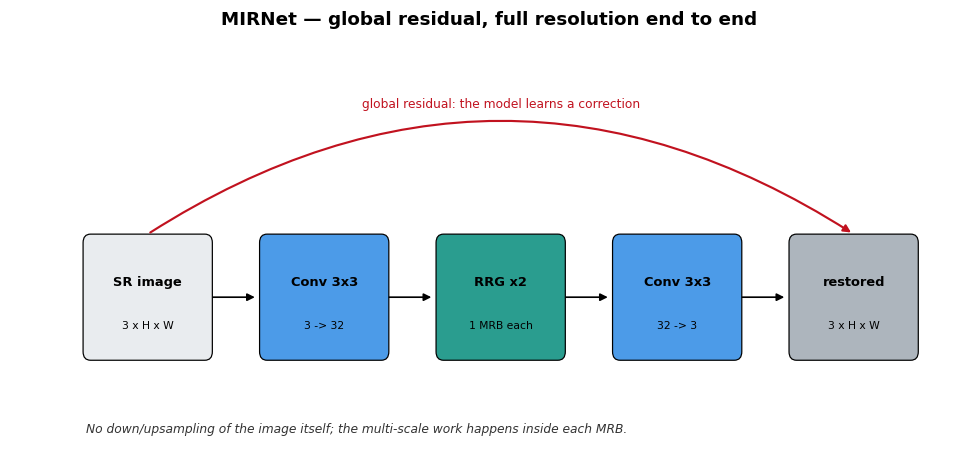

  saved -> outputs\figures\B_mrb.png


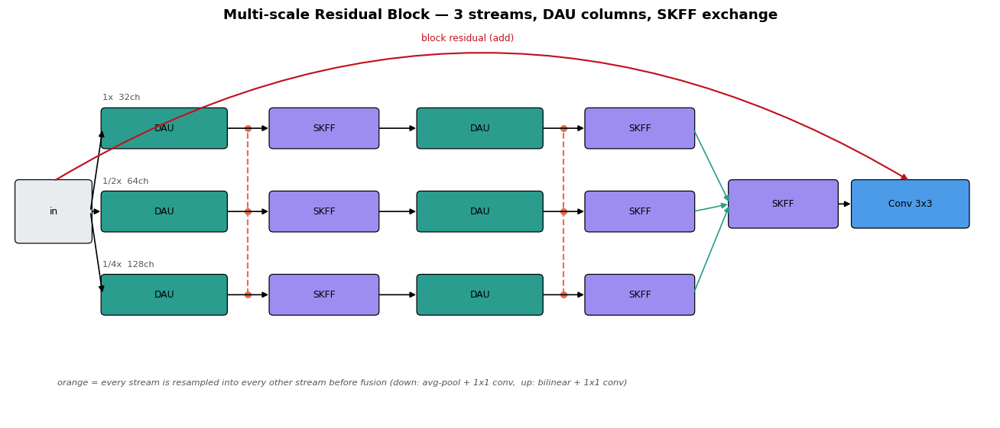

MIRNet - input (3, 64, 64) -> output (3, 64, 64)
layer                     output shape                params
------------------------------------------------------------
Conv2d_0                  (32, 64, 64)                   896
AvgPool2d_1               (32, 32, 32)                     0
Conv2d_2                  (64, 32, 32)                 2,048
PReLU_3                   (64, 32, 32)                     1
AvgPool2d_4               (32, 32, 32)                     0
Conv2d_5                  (64, 32, 32)                 2,048
PReLU_6                   (64, 32, 32)                     1
AvgPool2d_7               (64, 16, 16)                     0
Conv2d_8                  (128, 16, 16)                8,192
PReLU_9                   (128, 16, 16)                    1
Conv2d_10                 (32, 64, 64)                 9,248
PReLU_11                  (32, 64, 64)                     1
Conv2d_12                 (32, 64, 64)                 9,248
AdaptiveAvgPool2d_13      (32, 1, 1)

'MIRNet - input (3, 64, 64) -> output (3, 64, 64)\nlayer                     output shape                params\n------------------------------------------------------------\nConv2d_0                  (32, 64, 64)                   896\nAvgPool2d_1               (32, 32, 32)                     0\nConv2d_2                  (64, 32, 32)                 2,048\nPReLU_3                   (64, 32, 32)                     1\nAvgPool2d_4               (32, 32, 32)                     0\nConv2d_5                  (64, 32, 32)                 2,048\nPReLU_6                   (64, 32, 32)                     1\nAvgPool2d_7               (64, 16, 16)                     0\nConv2d_8                  (128, 16, 16)                8,192\nPReLU_9                   (128, 16, 16)                    1\nConv2d_10                 (32, 64, 64)                 9,248\nPReLU_11                  (32, 64, 64)                     1\nConv2d_12                 (32, 64, 64)                 9,248\nAdaptiveAvgPool2d_1

In [24]:
draw_architecture(
    [("input",  "SR image",     "3 x H x W"),
     ("conv",   "Conv 3x3",     f"3 -> {SCFG.n_feat}"),
     ("res",    "RRG x" + str(SCFG.n_RRG), f"{SCFG.n_MRB} MRB each"),
     ("conv",   "Conv 3x3",     f"{SCFG.n_feat} -> 3"),
     ("output", "restored",     "3 x H x W")],
    "MIRNet — global residual, full resolution end to end",
    "B_mirnet_top",
    skips=[(0, 4, "global residual: the model learns a correction")],
    note="No down/upsampling of the image itself; the multi-scale work happens inside each MRB.")


def draw_mrb():
    fig, ax = plt.subplots(figsize=(12, 5.2))
    ax.set_xlim(0, 12); ax.set_ylim(0, 5.2); ax.axis("off"); ax.grid(False)

    def box(x, y, w, h, text, color, fs=8):
        ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h,
                     boxstyle="round,pad=0.02,rounding_size=0.05",
                     facecolor=color, edgecolor="black", linewidth=.8))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

    def arrow(x0, y0, x1, y1, color="black", style="-|>", lw=1.1, rad=0.0):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle=style, color=color, lw=lw,
                                    connectionstyle=f"arc3,rad={rad}"))

    ys = [3.6, 2.5, 1.4]
    labels = [f"1x  {SCFG.n_feat}ch", f"1/2x  {SCFG.n_feat*2}ch", f"1/4x  {SCFG.n_feat*4}ch"]
    box(0.1, 2.35, 0.9, 0.8, "in", BLOCK_COLORS["input"])
    for y, lab in zip(ys, labels):
        ax.text(1.15, y + 0.62, lab, fontsize=7.5, color="#555555")
        box(1.15, y, 1.5, 0.5, "DAU", BLOCK_COLORS["res"])
        box(3.2, y, 1.3, 0.5, "SKFF", BLOCK_COLORS["norm"])
        box(5.0, y, 1.5, 0.5, "DAU", BLOCK_COLORS["res"])
        box(7.05, y, 1.3, 0.5, "SKFF", BLOCK_COLORS["norm"])
        arrow(1.0, 2.75, 1.15, y + 0.25)
        arrow(2.65, y + 0.25, 3.2, y + 0.25)
        arrow(4.5, y + 0.25, 5.0, y + 0.25)
        arrow(6.5, y + 0.25, 7.05, y + 0.25)
        arrow(8.35, y + 0.25, 8.8, 2.85, "#2a9d8f")
    for xline in (2.92, 6.77):                    # the all-to-all exchange before each SKFF
        ax.plot([xline, xline], [ys[2] + 0.25, ys[0] + 0.25], color="#e76f51", lw=1.4, ls="--")
        for y in ys:
            ax.plot([xline], [y + 0.25], marker="o", ms=5, color="#e76f51")
    box(8.8, 2.55, 1.3, 0.6, "SKFF", BLOCK_COLORS["norm"])
    box(10.3, 2.55, 1.4, 0.6, "Conv 3x3", BLOCK_COLORS["conv"])
    arrow(10.1, 2.85, 10.3, 2.85)
    arrow(0.55, 3.15, 11.0, 3.15, "#c1121f", lw=1.4, rad=-0.30)   # arcs clear of the top row
    ax.text(5.6, 5.0, "block residual (add)", color="#c1121f", fontsize=8, ha="center")
    ax.text(0.6, 0.45, "orange = every stream is resampled into every other stream before fusion "
                       "(down: avg-pool + 1x1 conv,  up: bilinear + 1x1 conv)",
            fontsize=7.5, style="italic", color="#555555")
    ax.set_title("Multi-scale Residual Block — 3 streams, DAU columns, SKFF exchange",
                 fontsize=12, fontweight="bold")
    plt.tight_layout()
    savefig(fig, "B_mrb")
    plt.show()


draw_mrb()
model_summary(MIRNet().to(device), "MIRNet", input_shape=(1, 3, 64, 64))

## 17. What MIRNet is trained on

MIRNet has to do two jobs, so it is trained on both, in a fixed round-robin so every job gets the
same number of gradient steps:

| Source | Input built from a clean HR patch by | Job |
|---|---|---|
| `SRCNN … EDSR` | bicubic ↓4, then the frozen network ↑4 | remove that network's artefacts |
| `Bicubic` | bicubic ↓4 then bicubic ↑4 | the no-network baseline |
| `NoiseBlur` | Gaussian blur σ∈[0.6,1.6] + Gaussian noise σ∈[4,16]/255 | classical **restoration** |
| `LowLight` | γ∈[1.2,1.8] gamma compression, gain ∈[0.5,0.8], mild noise | classical **enhancement** |

Target is always the clean HR patch. Six of the eight sources are super-resolution outputs, which
is where the assignment's questions live; the other two keep the network an honest general
restoration model rather than an SR-artefact specialist, and give Task 3 something to be evaluated
on in its own right. The under-exposure is kept mild on purpose — a heavy one carries a far larger
loss than any SR artefact, and one shared model would spend its capacity on brightening.

Loss is **Charbonnier**, `√((x−y)² + ε²)` — the differentiable L1 that MIRNet, EDSR and most
restoration work use. L1-like losses beat L2 here because L2 averages plausible textures into
mush, which is precisely the artefact being removed.

  saved -> outputs\figures\B_training_sources.png


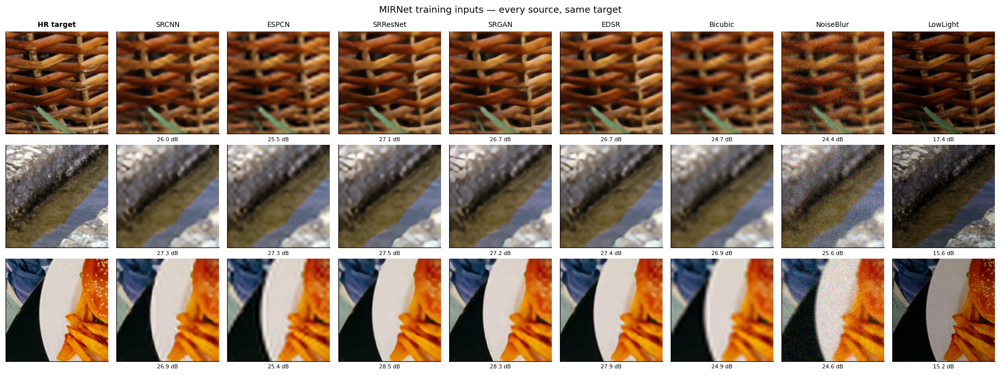

In [25]:
DEGRADATIONS = ["NoiseBlur", "LowLight"]
SOURCES = SR_NAMES + ["Bicubic"] + DEGRADATIONS


def _gauss_kernel(sigma: float, ksize: int = 7, device=device) -> torch.Tensor:
    ax = torch.arange(ksize, dtype=torch.float32, device=device) - (ksize - 1) / 2
    k = torch.exp(-(ax ** 2) / (2 * sigma ** 2))
    k = (k / k.sum())
    return (k[:, None] * k[None, :]).view(1, 1, ksize, ksize)


def gaussian_blur(x: torch.Tensor, sigma: float, ksize: int = 7) -> torch.Tensor:
    k = _gauss_kernel(sigma, ksize).expand(x.shape[1], 1, ksize, ksize)
    return F.conv2d(F.pad(x, (ksize // 2,) * 4, mode="reflect"), k, groups=x.shape[1])


def bicubic_down_t(hr: torch.Tensor, scale: int = None) -> torch.Tensor:
    """Antialiased bicubic decimation on the GPU — the tensor equivalent of PIL's BICUBIC."""
    scale = scale or SCFG.scale
    return F.interpolate(hr, scale_factor=1 / scale, mode="bicubic",
                         align_corners=False, antialias=True).clamp(0, 1)


def bicubic_up_t(lr: torch.Tensor, scale: int = None) -> torch.Tensor:
    scale = scale or SCFG.scale
    return F.interpolate(lr, scale_factor=scale, mode="bicubic", align_corners=False).clamp(0, 1)


@torch.no_grad()
def make_input(hr: torch.Tensor, source: str, gen: torch.Generator = None) -> torch.Tensor:
    """Build MIRNet's input from a clean HR batch, according to `source`."""
    if source in SR_NAMES:
        return sr_models[source](bicubic_down_t(hr)).clamp(0, 1)
    if source == "Bicubic":
        return bicubic_up_t(bicubic_down_t(hr))
    if source == "NoiseBlur":
        x = gaussian_blur(hr, sigma=float(torch.empty(1).uniform_(0.6, 1.6)))
        return (x + torch.randn_like(x) * float(torch.empty(1).uniform_(4, 16)) / 255).clamp(0, 1)
    if source == "LowLight":
        # deliberately mild. A heavy under-exposure has a much larger Charbonnier loss than any
        # SR artefact, and with a single shared model those batches would dominate the gradient
        # and pull MIRNet toward "brighten everything" — visible as washed-out SR restorations.
        gamma = float(torch.empty(1).uniform_(1.2, 1.8))
        gain = float(torch.empty(1).uniform_(0.5, 0.8))
        x = (hr.clamp_min(1e-6) ** gamma) * gain
        return (x + torch.randn_like(x) * float(torch.empty(1).uniform_(2, 8)) / 255).clamp(0, 1)
    raise ValueError(source)


def charbonnier(pred, target, eps=1e-3):
    return torch.sqrt((pred - target) ** 2 + eps ** 2).mean()


def show_training_sources(n=3):
    """One clean patch, all eight degradations, with the PSNR each one starts from."""
    hr = val_hr[:n]
    fig, axes = plt.subplots(n, len(SOURCES) + 1, figsize=(2.0 * (len(SOURCES) + 1), 2.25 * n))
    axes = np.atleast_2d(axes)
    for r in range(n):
        axes[r, 0].imshow(hr[r].cpu().permute(1, 2, 0).numpy())
        axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([]); axes[r, 0].grid(False)
        if r == 0:
            axes[r, 0].set_title("HR target", fontsize=9, fontweight="bold")
    for c, src in enumerate(SOURCES, start=1):
        deg = make_input(hr, src)
        for r in range(n):
            ax = axes[r, c]
            ax.imshow(deg[r].cpu().permute(1, 2, 0).numpy())
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            ax.set_xlabel(f"{psnr(deg[r], hr[r]):.1f} dB", fontsize=7)
            if r == 0:
                ax.set_title(src, fontsize=9)
    fig.suptitle("MIRNet training inputs — every source, same target", fontsize=12)
    plt.tight_layout()
    savefig(fig, "B_training_sources")
    plt.show()


show_training_sources()

## 18. Training MIRNet

Adam, cosine decay from 2e-4, mixed precision, patches shuffled every epoch. The source cycles
`SRCNN → ESPCN → SRResNet → SRGAN → EDSR → Bicubic → NoiseBlur → LowLight` across consecutive
batches, so within an epoch each source contributes the same number of updates regardless of how
the batches fall.

In [26]:
def mirnet_train():
    model = MIRNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=SCFG.lr, betas=(0.9, 0.999))
    n_batches = math.ceil(len(train_hr) / SCFG.batch_size)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=SCFG.epochs * n_batches, eta_min=SCFG.min_lr)
    scaler = torch.amp.GradScaler("cuda", enabled=(CCFG.amp and device.type == "cuda"))

    hist = {"loss": [], "val_psnr": [], "epoch_s": [], "lr": []}
    best, best_state, t_start, step = -1.0, None, time.perf_counter(), 0

    for ep in range(1, SCFG.epochs + 1):
        model.train()
        t0 = time.perf_counter()
        order = torch.randperm(len(train_hr))
        run_loss, seen = 0.0, 0
        for bi in range(n_batches):
            idx = order[bi * SCFG.batch_size:(bi + 1) * SCFG.batch_size]
            hr = train_hr[idx].to(device, non_blocking=True).float() / 255.0
            if random.random() < 0.5:
                hr = hr.flip(-1)
            if random.random() < 0.5:
                hr = hr.flip(-2)
            src = SOURCES[step % len(SOURCES)]              # round-robin over the eight sources
            lq = make_input(hr, src)

            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=(CCFG.amp and device.type == "cuda")):
                out = model(lq)
                loss = charbonnier(out.float(), hr)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += float(loss) * hr.size(0); seen += hr.size(0); step += 1

        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_s = time.perf_counter() - t0

        # validation: mean PSNR over the eight sources, on held-out patches
        model.eval()
        vals = []
        with torch.no_grad():
            for src in SOURCES:
                acc = []
                for k in range(0, min(len(val_hr), 64), 8):
                    hr = val_hr[k:k + 8]
                    acc.append(batch_psnr(model(make_input(hr, src)).clamp(0, 1), hr))
                vals.append(float(np.mean(acc)))
        vpsnr = float(np.mean(vals))

        hist["loss"].append(run_loss / seen); hist["val_psnr"].append(vpsnr)
        hist["epoch_s"].append(epoch_s); hist["lr"].append(sched.get_last_lr()[0])
        if vpsnr > best:
            best = vpsnr
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ep <= 3 or ep % 5 == 0 or ep == SCFG.epochs:
            print(f"  epoch {ep:3d}/{SCFG.epochs}  loss {run_loss/seen:.5f}   "
                  f"val PSNR {vpsnr:6.2f} dB   {epoch_s:5.1f}s")

    total_s = time.perf_counter() - t_start
    model.load_state_dict(best_state)
    torch.save(best_state, CKPTDIR / "MIRNet.pth")
    hist["total_s"], hist["best_val_psnr"] = total_s, best
    print(f"\nMIRNet trained in {hhmmss(total_s)} ({np.mean(hist['epoch_s']):.1f}s/epoch), "
          f"best val PSNR {best:.2f} dB")
    print(f"  saved -> {CKPTDIR / 'MIRNet.pth'}")
    return model, hist


RETRAIN_MIRNET = True          # False -> reuse outputs/checkpoints/MIRNet.pth if it exists

if RETRAIN_MIRNET or not (CKPTDIR / "MIRNet.pth").exists():
    mirnet, mirnet_hist = mirnet_train()
    json.dump(mirnet_hist, open(RESDIR / "B_mirnet_history.json", "w"), indent=2)
else:
    mirnet = MIRNet().to(device)
    mirnet.load_state_dict(torch.load(CKPTDIR / "MIRNet.pth", map_location=device))
    mirnet_hist = json.load(open(RESDIR / "B_mirnet_history.json"))
    print("reused checkpoint", CKPTDIR / "MIRNet.pth")

mirnet.eval()
for _p in mirnet.parameters():
    _p.requires_grad_(False)
print(f"MIRNet ready: {count_params(mirnet, trainable_only=False):,} parameters")

  epoch   1/60  loss 0.06238   val PSNR  24.77 dB    34.9s
  epoch   2/60  loss 0.05952   val PSNR  25.21 dB    34.4s
  epoch   3/60  loss 0.05771   val PSNR  25.35 dB    34.5s
  epoch   5/60  loss 0.05840   val PSNR  25.25 dB    34.3s
  epoch  10/60  loss 0.05416   val PSNR  25.35 dB    33.9s
  epoch  15/60  loss 0.04854   val PSNR  25.92 dB    33.4s
  epoch  20/60  loss 0.04654   val PSNR  26.30 dB    34.6s
  epoch  25/60  loss 0.04333   val PSNR  26.56 dB    33.3s
  epoch  30/60  loss 0.04485   val PSNR  26.44 dB    33.2s
  epoch  35/60  loss 0.04263   val PSNR  26.51 dB    34.0s
  epoch  40/60  loss 0.04096   val PSNR  26.46 dB    34.0s
  epoch  45/60  loss 0.04085   val PSNR  26.57 dB    34.2s
  epoch  50/60  loss 0.04009   val PSNR  26.90 dB    35.4s
  epoch  55/60  loss 0.03944   val PSNR  26.81 dB    35.5s
  epoch  60/60  loss 0.04000   val PSNR  27.10 dB    35.5s

MIRNet trained in 35m 29.3s (34.2s/epoch), best val PSNR 27.10 dB
  saved -> outputs\checkpoints\MIRNet.pth
MIRNet

  saved -> outputs\figures\B_mirnet_training.png


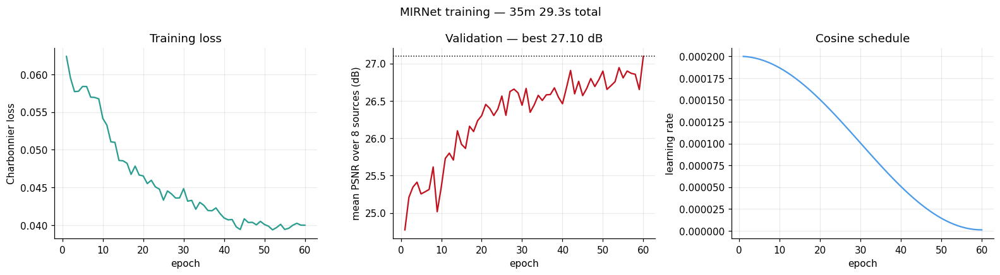

In [27]:
def plot_mirnet_training():
    h = mirnet_hist
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4))
    ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], color="#2a9d8f")
    axes[0].set(xlabel="epoch", ylabel="Charbonnier loss", title="Training loss")
    axes[1].plot(ep, h["val_psnr"], color="#c1121f")
    axes[1].axhline(max(h["val_psnr"]), ls=":", color="black", lw=1)
    axes[1].set(xlabel="epoch", ylabel="mean PSNR over 8 sources (dB)",
                title=f"Validation — best {max(h['val_psnr']):.2f} dB")
    axes[2].plot(ep, h["lr"], color="#4c9be8")
    axes[2].set(xlabel="epoch", ylabel="learning rate", title="Cosine schedule")
    fig.suptitle(f"MIRNet training — {hhmmss(h['total_s'])} total", fontsize=12)
    plt.tight_layout()
    savefig(fig, "B_mirnet_training")
    plt.show()


plot_mirnet_training()

## 19. Task 3 — MIRNet on its own

Before it is bolted onto anything, MIRNet is evaluated as a restoration and enhancement network:
for each of the eight degradation sources, on held-out validation patches, PSNR/SSIM/LPIPS of the
degraded input against the ground truth, and of MIRNet's output against the same ground truth.

The `NoiseBlur` and `LowLight` rows answer "is this a working restoration/enhancement network?".
The six super-resolution rows are the baseline for Tasks 4–7.

In [28]:
@torch.no_grad()
def evaluate_mirnet_standalone(n_patches=None):
    n = min(n_patches or len(val_hr), len(val_hr))
    rows = []
    for src in SOURCES:
        for k in range(0, n, 8):
            hr = val_hr[k:k + 8]
            lq = make_input(hr, src)
            out = mirnet(lq).clamp(0, 1)
            for b in range(hr.shape[0]):
                rows.append(dict(Source=src, Stage="before", **image_metrics(lq[b], hr[b])))
                rows.append(dict(Source=src, Stage="after",  **image_metrics(out[b], hr[b])))
    return pd.DataFrame(rows)


standalone_raw = evaluate_mirnet_standalone(64 if not QUICK_MODE else 16)
standalone = (standalone_raw.groupby(["Source", "Stage"])[["PSNR", "SSIM", "LPIPS"]]
              .mean().round(4).reset_index())
standalone_wide = standalone.pivot(index="Source", columns="Stage",
                                   values=["PSNR", "SSIM", "LPIPS"])
standalone_wide.columns = [f"{m}_{s}" for m, s in standalone_wide.columns]
standalone_wide = standalone_wide.reindex(SOURCES).reset_index()
standalone_wide["dPSNR"] = (standalone_wide.PSNR_after - standalone_wide.PSNR_before).round(3)
standalone_wide["dSSIM"] = (standalone_wide.SSIM_after - standalone_wide.SSIM_before).round(4)
standalone_wide["dLPIPS"] = (standalone_wide.LPIPS_after - standalone_wide.LPIPS_before).round(4)
save_table(standalone_wide, "B_mirnet_standalone")
print()
print(standalone_wide.to_string(index=False))

  saved -> outputs\results\B_mirnet_standalone.csv

   Source  PSNR_after  PSNR_before  SSIM_after  SSIM_before  LPIPS_after  LPIPS_before  dPSNR  dSSIM  dLPIPS
    SRCNN     28.7088      28.7608      0.7582       0.7551       0.2847        0.2953 -0.052 0.0031 -0.0106
    ESPCN     28.3696      28.1378      0.7492       0.7388       0.3285        0.3577  0.232 0.0104 -0.0292
 SRResNet     29.4570      29.6194      0.7869       0.7868       0.2504        0.2506 -0.162 0.0001 -0.0002
    SRGAN     29.3268      29.3121      0.7838       0.7791       0.2323        0.2126  0.015 0.0047  0.0197
     EDSR     29.2785      29.3886      0.7788       0.7766       0.2642        0.2686 -0.110 0.0022 -0.0044
  Bicubic     28.1369      27.8486      0.7250       0.7140       0.3775        0.4065  0.288 0.0110 -0.0290
NoiseBlur     29.1712      28.5755      0.8256       0.7268       0.2282        0.2701  0.596 0.0988 -0.0419
 LowLight     25.3876      14.5754      0.8961       0.7064       0.1267    

  saved -> outputs\figures\B_mirnet_standalone.png


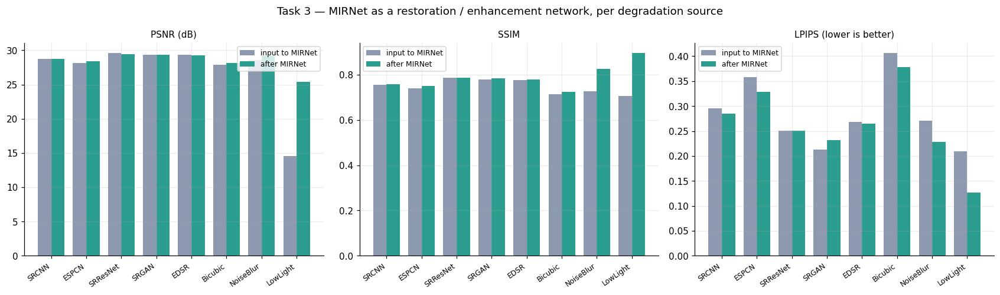

  saved -> outputs\figures\B_mirnet_standalone_examples_0.png


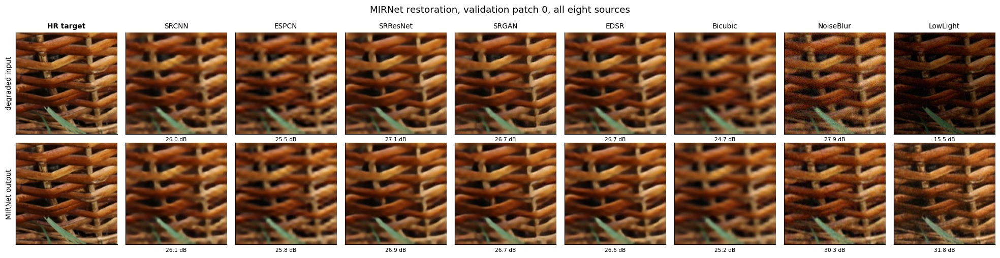

  saved -> outputs\figures\B_mirnet_standalone_examples_7.png


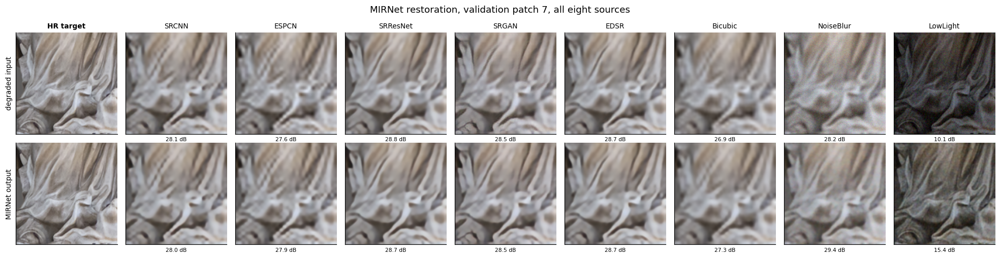

In [29]:
def plot_standalone():
    d = standalone_wide.set_index("Source").reindex(SOURCES)
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
    xs = np.arange(len(SOURCES)); w = 0.38
    panels = [("PSNR (dB)", "PSNR_before", "PSNR_after", False),
              ("SSIM", "SSIM_before", "SSIM_after", False),
              ("LPIPS (lower is better)", "LPIPS_before", "LPIPS_after", True)]
    for ax, (title, cb, ca, lower_better) in zip(axes, panels):
        ax.bar(xs - w / 2, d[cb], w, label="input to MIRNet", color="#8d99ae")
        ax.bar(xs + w / 2, d[ca], w, label="after MIRNet", color="#2a9d8f")
        ax.set_xticks(xs); ax.set_xticklabels(SOURCES, rotation=35, ha="right", fontsize=8)
        ax.set_title(title, fontsize=10)
        ax.legend(fontsize=8)
    fig.suptitle("Task 3 — MIRNet as a restoration / enhancement network, per degradation source",
                 fontsize=12)
    plt.tight_layout()
    savefig(fig, "B_mirnet_standalone")
    plt.show()


def show_standalone_examples(idx=0):
    hr = val_hr[idx:idx + 1]
    fig, axes = plt.subplots(2, len(SOURCES) + 1, figsize=(2.0 * (len(SOURCES) + 1), 4.6))
    for r in range(2):
        axes[r, 0].imshow(hr[0].cpu().permute(1, 2, 0).numpy())
        axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([]); axes[r, 0].grid(False)
    axes[0, 0].set_title("HR target", fontsize=9, fontweight="bold")
    axes[0, 0].set_ylabel("degraded input", fontsize=9)
    axes[1, 0].set_ylabel("MIRNet output", fontsize=9)
    with torch.no_grad():
        for c, src in enumerate(SOURCES, start=1):
            lq = make_input(hr, src)
            out = mirnet(lq).clamp(0, 1)
            for r, t in enumerate((lq, out)):
                ax = axes[r, c]
                ax.imshow(t[0].cpu().permute(1, 2, 0).numpy())
                ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
                ax.set_xlabel(f"{psnr(t[0], hr[0]):.1f} dB", fontsize=7)
            axes[0, c].set_title(src, fontsize=9)
    fig.suptitle(f"MIRNet restoration, validation patch {idx}, all eight sources", fontsize=12)
    plt.tight_layout()
    savefig(fig, f"B_mirnet_standalone_examples_{idx}")
    plt.show()


plot_standalone()
show_standalone_examples(0)
show_standalone_examples(7)

## 20. Tasks 4–6 — the five pipelines on full images

The protocol, per test image:

1. crop the HR image to a multiple of 4 and cap its long side at `max_eval_side`;
2. `LR = bicubic ↓4` (PIL, the same degradation Assignment 2 trained on);
3. for each of bicubic and the five networks: `SR = method(LR)` → **before** metrics;
4. `restored = MIRNet(SR)` → **after** metrics;
5. record both, plus the wall-clock cost of each stage.

MIRNet is applied to whole images, reflect-padded to a multiple of 4 and cropped back. Images
larger than `TILE_THRESHOLD` pixels are processed in overlapping tiles so memory does not depend on
image size.

In [30]:
TILE_THRESHOLD = 1024 * 1024      # pixels; above this, MIRNet runs tile-by-tile
TILE, TILE_OVERLAP = 512, 32


@torch.no_grad()
def mirnet_apply(x: torch.Tensor) -> torch.Tensor:
    """MIRNet on a (3,H,W) or (B,3,H,W) tensor of any size, in [0,1]."""
    single = x.dim() == 3
    x = x[None] if single else x
    m = mirnet.multiple
    ph, pw = (-x.shape[-2]) % m, (-x.shape[-1]) % m
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode="reflect")
    if x.shape[-1] * x.shape[-2] <= TILE_THRESHOLD:
        y = mirnet(x)
    else:                                            # overlapping tiles, cosine-free blend by crop
        y = torch.zeros_like(x)
        cnt = torch.zeros_like(x)
        step = TILE - TILE_OVERLAP
        for top in range(0, x.shape[-2], step):
            for left in range(0, x.shape[-1], step):
                t, l = min(top, max(0, x.shape[-2] - TILE)), min(left, max(0, x.shape[-1] - TILE))
                patch = x[..., t:t + TILE, l:l + TILE]
                y[..., t:t + TILE, l:l + TILE] += mirnet(patch)
                cnt[..., t:t + TILE, l:l + TILE] += 1
        y = y / cnt.clamp_min(1)
    y = y[..., :y.shape[-2] - ph if ph else y.shape[-2], :y.shape[-1] - pw if pw else y.shape[-1]]
    return y.clamp(0, 1)[0] if single else y.clamp(0, 1)


@torch.no_grad()
def sr_apply(method: str, lr: torch.Tensor) -> torch.Tensor:
    """Super-resolve a (3,h,w) LR tensor to (3,4h,4w)."""
    x = lr[None]
    return (bicubic_up_t(x) if method == "Bicubic" else sr_models[method](x).clamp(0, 1))[0]


def load_hr(path: Path, max_side: int = None) -> torch.Tensor:
    max_side = max_side or SCFG.max_eval_side
    img = Image.open(path).convert("RGB")
    if max(img.size) > max_side:
        s = max_side / max(img.size)
        img = img.resize((int(img.width * s), int(img.height * s)), Image.BICUBIC)
    return pil_to_tensor(crop_to_multiple(img, SCFG.scale * mirnet.multiple))


def make_lr(hr: torch.Tensor) -> torch.Tensor:
    return pil_to_tensor(bicubic_down_pil(tensor_to_pil(hr), SCFG.scale))


def _timed(fn, *a):
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = fn(*a)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return out, (time.perf_counter() - t0) * 1000


def evaluate_pipelines(paths: List[Path], tag: str) -> pd.DataFrame:
    """Per-image, per-method metrics before and after MIRNet."""
    rows = []
    for n, p in enumerate(paths, 1):
        hr = load_hr(p).to(device)
        lr = make_lr(hr.cpu()).to(device)
        for method in METHODS:
            sr, t_sr = _timed(sr_apply, method, lr)
            out, t_mir = _timed(mirnet_apply, sr)
            rows.append(dict(Set=tag, Image=p.name, Method=method, Stage="before",
                             **image_metrics(sr, hr), Time_ms=round(t_sr, 2)))
            rows.append(dict(Set=tag, Image=p.name, Method=method, Stage="after",
                             **image_metrics(out, hr), Time_ms=round(t_sr + t_mir, 2)))
        print(f"  [{tag}] {n}/{len(paths)}  {p.name}  ({tuple(hr.shape[1:])})")
        del hr, lr
        if device.type == "cuda":
            torch.cuda.empty_cache()
    return pd.DataFrame(rows)


print(f"evaluating {len(EVAL_IMAGES)} DIV2K validation images "
      f"x {len(METHODS)} methods x 2 stages")
pipe_div2k = evaluate_pipelines(EVAL_IMAGES, "DIV2K-valid")
pipe_all = pipe_div2k
if SMARTPHONE_IMAGES:
    print(f"\nevaluating {len(SMARTPHONE_IMAGES)} real photographs")
    pipe_phone = evaluate_pipelines(SMARTPHONE_IMAGES, "Smartphone")
    pipe_all = pd.concat([pipe_div2k, pipe_phone], ignore_index=True)
save_table(pipe_all, "B_pipeline_per_image")
print(f"\n{len(pipe_all)} rows recorded")

evaluating 20 DIV2K validation images x 6 methods x 2 stages
  [DIV2K-valid] 1/20  0801.png  ((336, 512))
  [DIV2K-valid] 2/20  0802.png  ((336, 512))
  [DIV2K-valid] 3/20  0803.png  ((384, 512))
  [DIV2K-valid] 4/20  0804.png  ((288, 512))
  [DIV2K-valid] 5/20  0805.png  ((384, 512))
  [DIV2K-valid] 6/20  0806.png  ((336, 512))
  [DIV2K-valid] 7/20  0807.png  ((272, 512))
  [DIV2K-valid] 8/20  0808.png  ((336, 512))
  [DIV2K-valid] 9/20  0809.png  ((336, 512))
  [DIV2K-valid] 10/20  0810.png  ((384, 512))
  [DIV2K-valid] 11/20  0811.png  ((336, 512))
  [DIV2K-valid] 12/20  0812.png  ((384, 512))
  [DIV2K-valid] 13/20  0813.png  ((352, 512))
  [DIV2K-valid] 14/20  0814.png  ((336, 512))
  [DIV2K-valid] 15/20  0815.png  ((336, 512))
  [DIV2K-valid] 16/20  0816.png  ((336, 512))
  [DIV2K-valid] 17/20  0817.png  ((384, 512))
  [DIV2K-valid] 18/20  0818.png  ((384, 512))
  [DIV2K-valid] 19/20  0819.png  ((336, 512))
  [DIV2K-valid] 20/20  0820.png  ((336, 512))

evaluating 8 real photograp

In [31]:
def aggregate_pipelines(df: pd.DataFrame, tag: str) -> pd.DataFrame:
    d = df[df.Set == tag]
    agg = (d.groupby(["Method", "Stage"])[["PSNR", "SSIM", "LPIPS", "Time_ms"]]
           .mean().reset_index())
    wide = agg.pivot(index="Method", columns="Stage",
                     values=["PSNR", "SSIM", "LPIPS", "Time_ms"])
    wide.columns = [f"{m}_{s}" for m, s in wide.columns]
    wide = wide.reindex(METHODS).reset_index()
    wide["dPSNR"] = wide.PSNR_after - wide.PSNR_before
    wide["dSSIM"] = wide.SSIM_after - wide.SSIM_before
    wide["dLPIPS"] = wide.LPIPS_after - wide.LPIPS_before
    wide["Pipeline"] = [f"{m} -> MIRNet" for m in wide.Method]
    num = wide.select_dtypes("number").columns
    wide[num] = wide[num].round(4)
    return wide


agg_div2k = save_table(aggregate_pipelines(pipe_all, "DIV2K-valid"), "B_pipeline_summary_div2k")
print("\n=== DIV2K validation set: before vs after MIRNet ===")
print(agg_div2k[["Method", "PSNR_before", "PSNR_after", "dPSNR",
                 "SSIM_before", "SSIM_after", "dSSIM",
                 "LPIPS_before", "LPIPS_after", "dLPIPS"]].to_string(index=False))

if SMARTPHONE_IMAGES:
    agg_phone = save_table(aggregate_pipelines(pipe_all, "Smartphone"),
                           "B_pipeline_summary_smartphone")
    print("\n=== Smartphone photographs ===")
    print(agg_phone[["Method", "PSNR_before", "PSNR_after", "dPSNR",
                     "LPIPS_before", "LPIPS_after", "dLPIPS"]].to_string(index=False))

  saved -> outputs\results\B_pipeline_summary_div2k.csv

=== DIV2K validation set: before vs after MIRNet ===
  Method  PSNR_before  PSNR_after   dPSNR  SSIM_before  SSIM_after  dSSIM  LPIPS_before  LPIPS_after  dLPIPS
 Bicubic      25.6286     25.8469  0.2183       0.6992      0.7086 0.0094        0.4583       0.4314 -0.0269
   SRCNN      26.2980     26.2864 -0.0116       0.7349      0.7379 0.0031        0.3487       0.3372 -0.0115
   ESPCN      26.0550     26.2156  0.1606       0.7252      0.7341 0.0089        0.4069       0.3794 -0.0275
SRResNet      26.9506     26.8582 -0.0924       0.7613      0.7618 0.0005        0.3032       0.3022 -0.0010
   SRGAN      26.7066     26.7403  0.0337       0.7540      0.7583 0.0043        0.2601       0.2844  0.0243
    EDSR      26.7509     26.7043 -0.0466       0.7537      0.7555 0.0018        0.3203       0.3163 -0.0040
  saved -> outputs\results\B_pipeline_summary_smartphone.csv

=== Smartphone photographs ===
  Method  PSNR_before  PSNR_after 

  saved -> outputs\figures\B_pipeline_metrics_div2k_valid.png


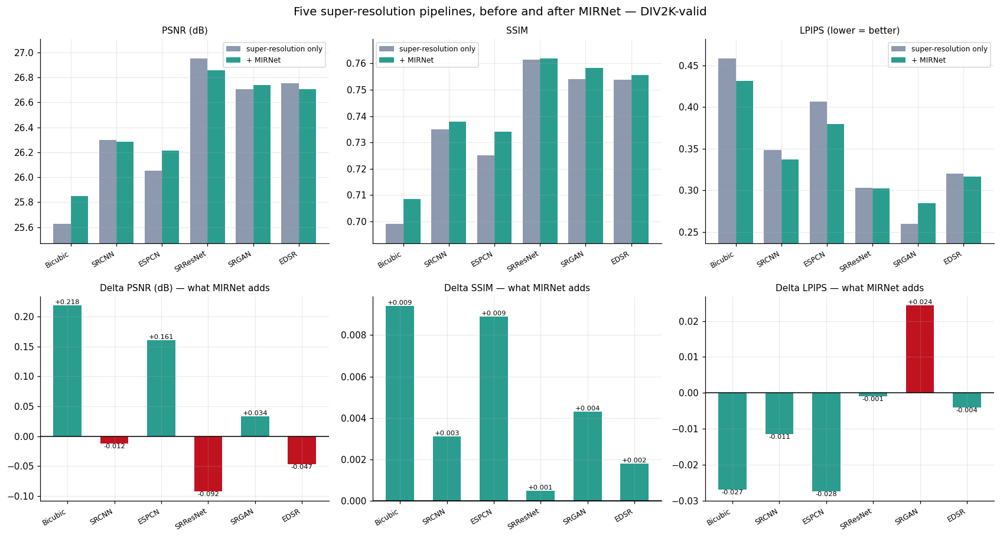

  saved -> outputs\figures\B_perception_distortion_div2k_valid.png


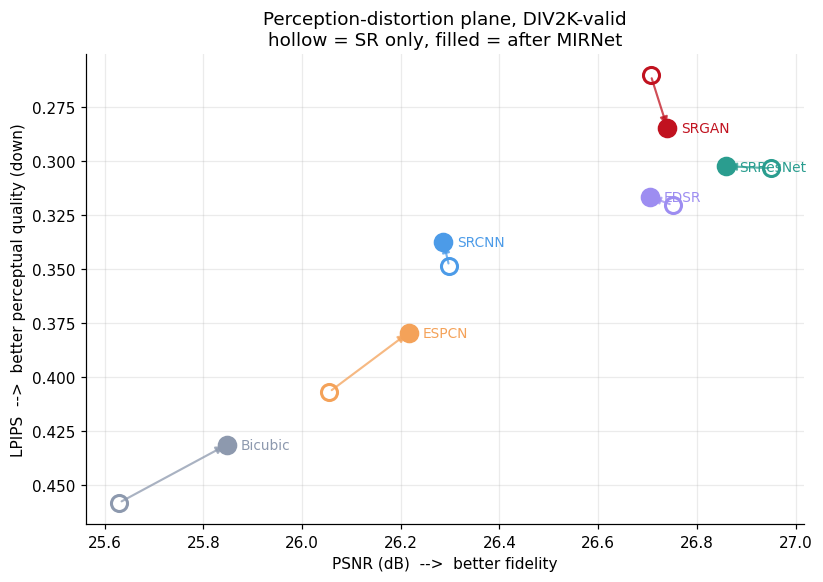

  saved -> outputs\figures\B_pipeline_spread_div2k_valid.png


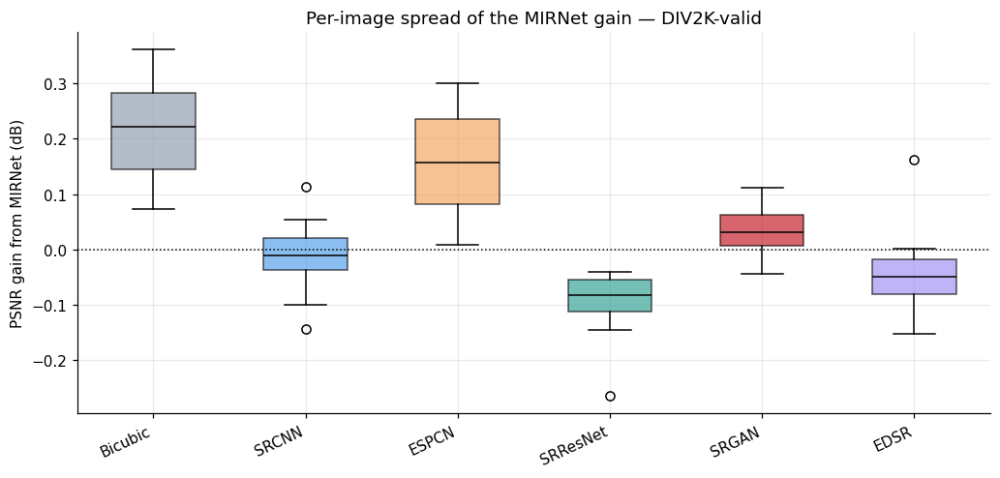

  saved -> outputs\figures\B_pipeline_metrics_smartphone.png


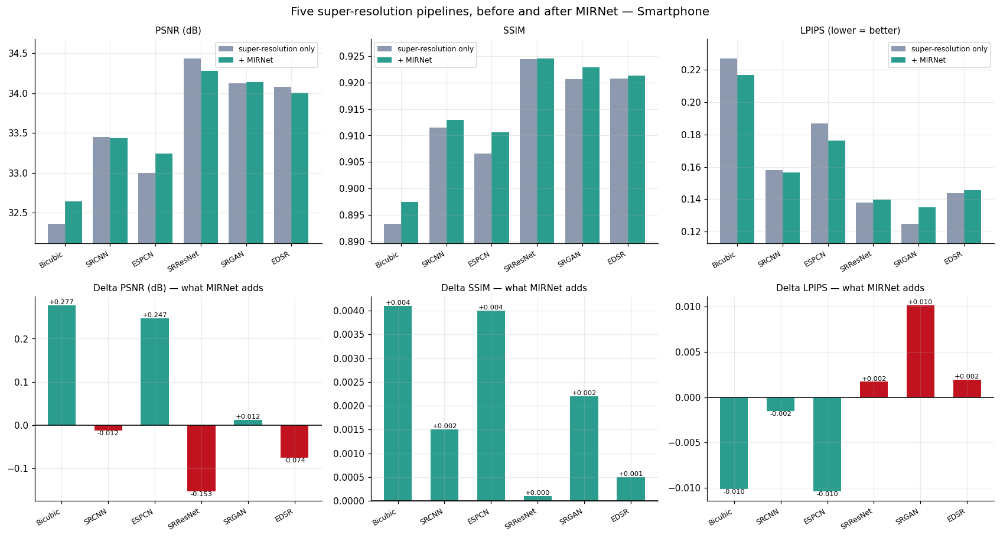

In [32]:
def plot_pipeline_metrics(agg: pd.DataFrame, tag: str):
    fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.4))
    xs = np.arange(len(METHODS)); w = 0.38

    for ax, (title, cb, ca) in zip(axes[0], [("PSNR (dB)", "PSNR_before", "PSNR_after"),
                                             ("SSIM", "SSIM_before", "SSIM_after"),
                                             ("LPIPS (lower = better)", "LPIPS_before",
                                              "LPIPS_after")]):
        ax.bar(xs - w / 2, agg[cb], w, label="super-resolution only", color="#8d99ae")
        ax.bar(xs + w / 2, agg[ca], w, label="+ MIRNet", color="#2a9d8f")
        ax.set_xticks(xs); ax.set_xticklabels(METHODS, rotation=30, ha="right", fontsize=8)
        ax.set_title(title, fontsize=10); ax.legend(fontsize=8)
        lo = min(agg[cb].min(), agg[ca].min()); hi = max(agg[cb].max(), agg[ca].max())
        ax.set_ylim(max(0, lo - 0.12 * (hi - lo + 1e-6)), hi + 0.12 * (hi - lo + 1e-6))

    for ax, (title, col, good_up) in zip(axes[1], [("Delta PSNR (dB)", "dPSNR", True),
                                                   ("Delta SSIM", "dSSIM", True),
                                                   ("Delta LPIPS", "dLPIPS", False)]):
        vals = agg[col].values
        good = vals > 0 if good_up else vals < 0
        ax.bar(xs, vals, 0.6, color=["#2a9d8f" if g else "#c1121f" for g in good])
        ax.axhline(0, color="black", lw=1)
        ax.set_xticks(xs); ax.set_xticklabels(METHODS, rotation=30, ha="right", fontsize=8)
        ax.set_title(f"{title} — what MIRNet adds", fontsize=10)
        for x, v in zip(xs, vals):
            ax.text(x, v, f"{v:+.3f}", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=7.5)

    fig.suptitle(f"Five super-resolution pipelines, before and after MIRNet — {tag}", fontsize=13)
    plt.tight_layout()
    savefig(fig, f"B_pipeline_metrics_{tag.lower().replace('-', '_')}")
    plt.show()


def plot_perception_distortion(agg: pd.DataFrame, tag: str):
    fig, ax = plt.subplots(figsize=(7.6, 5.4))
    for _, r in agg.iterrows():
        c = METHOD_COLORS[r.Method]
        ax.scatter(r.PSNR_before, r.LPIPS_before, s=110, facecolor="white", edgecolor=c, lw=2,
                   zorder=3)
        ax.scatter(r.PSNR_after, r.LPIPS_after, s=140, color=c, zorder=3)
        ax.annotate("", xy=(r.PSNR_after, r.LPIPS_after), xytext=(r.PSNR_before, r.LPIPS_before),
                    arrowprops=dict(arrowstyle="-|>", color=c, lw=1.4, alpha=0.75))
        ax.annotate(r.Method, (r.PSNR_after, r.LPIPS_after), textcoords="offset points",
                    xytext=(9, -3), fontsize=9, color=c)
    ax.set(xlabel="PSNR (dB)  -->  better fidelity",
           ylabel="LPIPS  -->  better perceptual quality (down)",
           title=f"Perception-distortion plane, {tag}\nhollow = SR only, filled = after MIRNet")
    ax.invert_yaxis()
    plt.tight_layout()
    savefig(fig, f"B_perception_distortion_{tag.lower().replace('-', '_')}")
    plt.show()


def plot_per_image_spread(tag: str):
    d = pipe_all[(pipe_all.Set == tag)]
    piv = d.pivot_table(index=["Image", "Method"], columns="Stage", values="PSNR").reset_index()
    piv["delta"] = piv.after - piv.before
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    data = [piv[piv.Method == m].delta.values for m in METHODS]
    bp = ax.boxplot(data, tick_labels=METHODS, patch_artist=True, widths=0.55)
    for patch, m in zip(bp["boxes"], METHODS):
        patch.set_facecolor(METHOD_COLORS[m]); patch.set_alpha(0.65)
    for med in bp["medians"]:
        med.set_color("black")
    ax.axhline(0, color="black", lw=1, ls=":")
    ax.set_ylabel("PSNR gain from MIRNet (dB)")
    ax.set_title(f"Per-image spread of the MIRNet gain — {tag}")
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
    plt.tight_layout()
    savefig(fig, f"B_pipeline_spread_{tag.lower().replace('-', '_')}")
    plt.show()


plot_pipeline_metrics(agg_div2k, "DIV2K-valid")
plot_perception_distortion(agg_div2k, "DIV2K-valid")
plot_per_image_spread("DIV2K-valid")
if SMARTPHONE_IMAGES:
    plot_pipeline_metrics(agg_phone, "Smartphone")

## 21. Task 5 — qualitative comparison

Metrics summarise; they do not show what a GAN artefact looks like or what MIRNet does to it. The
panels below take the most detailed crop of a test image (highest gradient energy, so no cherry-
picking) and show every method's output above its MIRNet-restored version, at 4× zoom.

  saved -> outputs\figures\B_context_div2k_0801.png


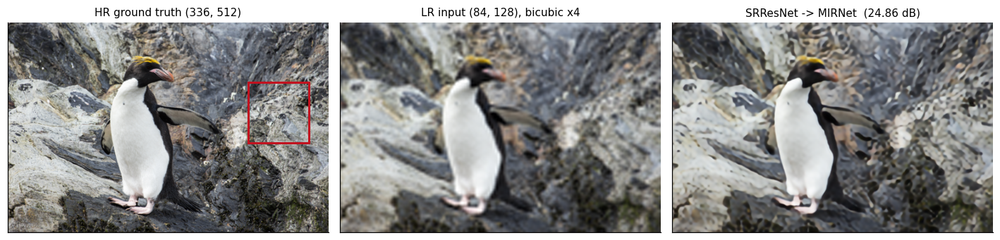

  saved -> outputs\figures\B_qualitative_div2k_0801.png


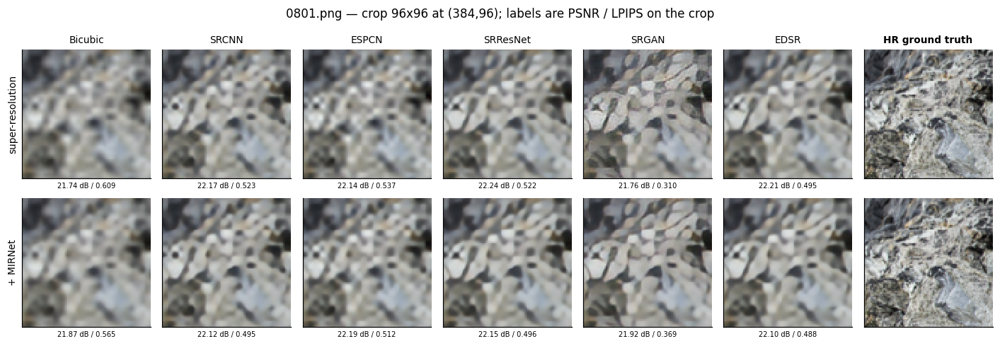

  saved -> outputs\figures\B_context_div2k_0802.png


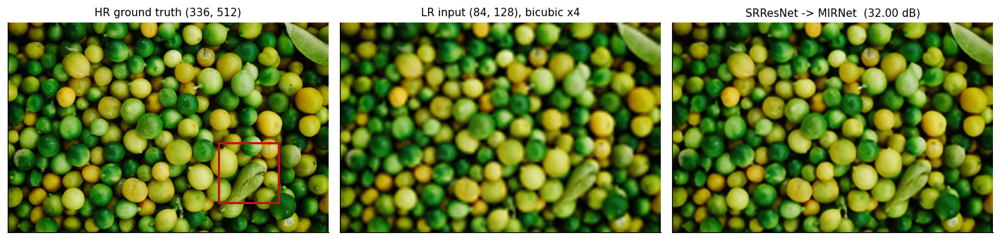

  saved -> outputs\figures\B_qualitative_div2k_0802.png


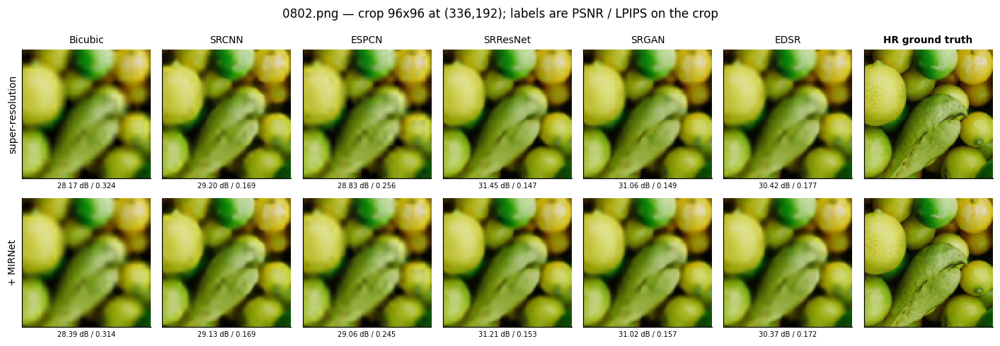

  saved -> outputs\figures\B_context_div2k_0803.png


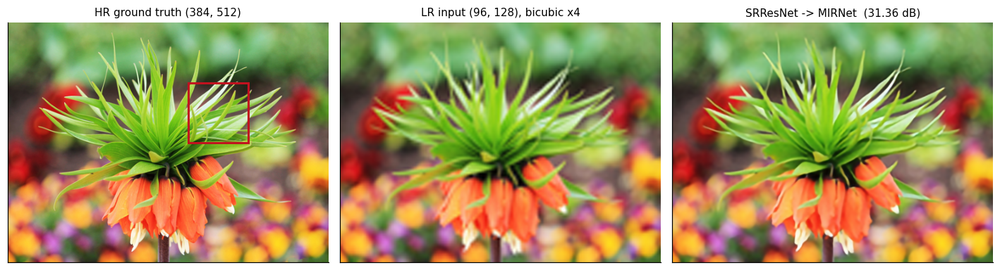

  saved -> outputs\figures\B_qualitative_div2k_0803.png


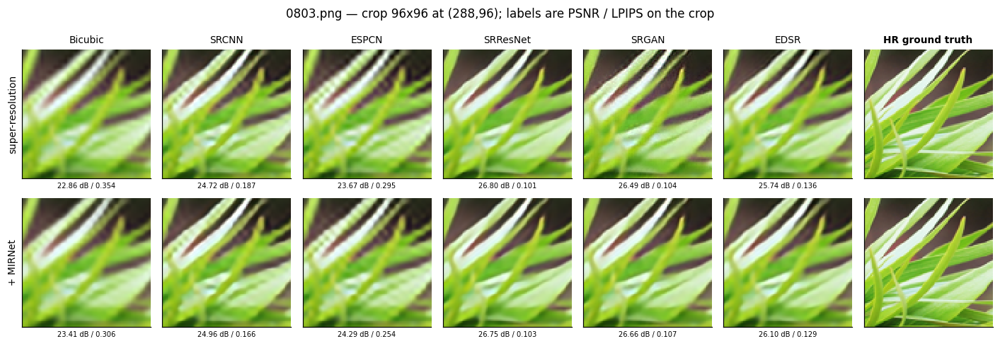

  saved -> outputs\figures\B_qualitative_phone_01.png


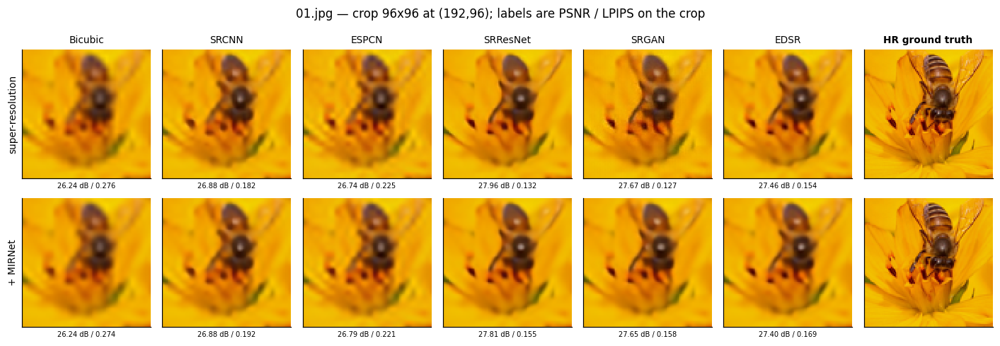

In [33]:
def best_crop_box(hr: torch.Tensor, size=96):
    """The window with the most gradient energy — texture, not sky, and no cherry-picking."""
    size = min(size, hr.shape[1], hr.shape[2])
    if min(hr.shape[1], hr.shape[2]) <= size:
        return 0, 0, size
    g = hr.mean(0)[None, None]
    grad = (g[..., 1:, 1:] - g[..., :-1, :-1]).abs()
    energy = F.avg_pool2d(grad, kernel_size=size, stride=size // 2)[0, 0]
    iy, ix = np.unravel_index(int(energy.argmax()), energy.shape)
    y = min(int(iy) * (size // 2), hr.shape[1] - size)
    x = min(int(ix) * (size // 2), hr.shape[2] - size)
    return y, x, size


@torch.no_grad()
def qualitative_panel(path: Path, tag: str, crop=96):
    hr = load_hr(path).to(device)
    lr = make_lr(hr.cpu()).to(device)
    y, x, s = best_crop_box(hr.cpu(), crop)

    cols = len(METHODS) + 1
    fig, axes = plt.subplots(2, cols, figsize=(1.85 * cols, 4.5))
    for c, method in enumerate(METHODS):
        sr = sr_apply(method, lr)
        out = mirnet_apply(sr)
        for r, t in enumerate((sr, out)):
            ax = axes[r, c]
            ax.imshow(t[:, y:y + s, x:x + s].cpu().permute(1, 2, 0).numpy(), interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            ax.set_xlabel(f"{psnr(t[:, y:y+s, x:x+s], hr[:, y:y+s, x:x+s], shave=0):.2f} dB / "
                          f"{lpips(t[:, y:y+s, x:x+s], hr[:, y:y+s, x:x+s]):.3f}", fontsize=6.5)
        axes[0, c].set_title(method, fontsize=9)
    for r in range(2):
        ax = axes[r, -1]
        ax.imshow(hr[:, y:y + s, x:x + s].cpu().permute(1, 2, 0).numpy(), interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    axes[0, -1].set_title("HR ground truth", fontsize=9, fontweight="bold")
    axes[0, 0].set_ylabel("super-resolution", fontsize=9)
    axes[1, 0].set_ylabel("+ MIRNet", fontsize=9)
    fig.suptitle(f"{path.name} — crop {s}x{s} at ({x},{y}); labels are PSNR / LPIPS on the crop",
                 fontsize=11)
    plt.tight_layout()
    savefig(fig, f"B_qualitative_{tag}_{path.stem}")
    plt.show()


@torch.no_grad()
def context_figure(path: Path, tag: str, crop=96):
    """Where the crop comes from, and the whole-image before/after for the best pipeline."""
    hr = load_hr(path).to(device)
    lr = make_lr(hr.cpu()).to(device)
    y, x, s = best_crop_box(hr.cpu(), crop)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
    axes[0].imshow(hr.cpu().permute(1, 2, 0).numpy())
    axes[0].add_patch(mpatches.Rectangle((x, y), s, s, fill=False, edgecolor="#c1121f", lw=2))
    axes[0].set_title(f"HR ground truth {tuple(hr.shape[1:])}", fontsize=10)
    axes[1].imshow(bicubic_up_t(lr[None])[0].cpu().permute(1, 2, 0).numpy())
    axes[1].set_title(f"LR input {tuple(lr.shape[1:])}, bicubic x4", fontsize=10)
    best = agg_div2k.sort_values("PSNR_after", ascending=False).Method.iloc[0]
    out = mirnet_apply(sr_apply(best, lr))
    axes[2].imshow(out.cpu().permute(1, 2, 0).numpy())
    axes[2].set_title(f"{best} -> MIRNet  ({psnr(out, hr):.2f} dB)", fontsize=10)
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    plt.tight_layout()
    savefig(fig, f"B_context_{tag}_{path.stem}")
    plt.show()


for _p in EVAL_IMAGES[:3]:
    context_figure(_p, "div2k")
    qualitative_panel(_p, "div2k")
if SMARTPHONE_IMAGES:
    qualitative_panel(SMARTPHONE_IMAGES[0], "phone")

## 22. Task 7 — which combination wins

Three metrics that do not agree cannot be collapsed by eye. Each pipeline is ranked on each metric
(PSNR ↑, SSIM ↑, LPIPS ↓) and the mean rank decides — a Borda count, which is robust to the very
different scales of the three metrics and does not silently weight dB against LPIPS units.

Two separate questions get separate answers:

* **best absolute quality** — the highest-scoring `X → MIRNet` pipeline;
* **best use of MIRNet** — the pipeline whose *gain* from MIRNet is largest, which is not
  necessarily the same one.

In [34]:
def rank_pipelines(agg: pd.DataFrame, tag: str) -> pd.DataFrame:
    d = agg.copy()
    d["rank_PSNR"] = d.PSNR_after.rank(ascending=False)
    d["rank_SSIM"] = d.SSIM_after.rank(ascending=False)
    d["rank_LPIPS"] = d.LPIPS_after.rank(ascending=True)
    d["MeanRank"] = d[["rank_PSNR", "rank_SSIM", "rank_LPIPS"]].mean(axis=1).round(2)
    d["GainRank"] = (d.dPSNR.rank(ascending=False)
                     + d.dSSIM.rank(ascending=False)
                     + d.dLPIPS.rank(ascending=True)).div(3).round(2)
    d = d.sort_values("MeanRank")
    out = d[["Pipeline", "PSNR_after", "SSIM_after", "LPIPS_after",
             "dPSNR", "dSSIM", "dLPIPS", "rank_PSNR", "rank_SSIM", "rank_LPIPS",
             "MeanRank", "GainRank"]]
    save_table(out, f"B_ranking_{tag}")
    return out


ranking = rank_pipelines(agg_div2k, "div2k")
print("\n=== Pipeline ranking on the DIV2K validation set (1 = best) ===")
print(ranking.to_string(index=False))

best_overall = ranking.iloc[0]
best_gain = ranking.sort_values("GainRank").iloc[0]
best_before = agg_div2k.sort_values("PSNR_before", ascending=False).iloc[0]
best_lpips = agg_div2k.sort_values("LPIPS_after").iloc[0]

verdict = {
    "best_pipeline_overall": best_overall.Pipeline,
    "best_pipeline_psnr_dB": float(best_overall.PSNR_after),
    "best_pipeline_ssim": float(best_overall.SSIM_after),
    "best_pipeline_lpips": float(best_overall.LPIPS_after),
    "best_perceptual_pipeline": f"{best_lpips.Method} -> MIRNet",
    "largest_gain_from_mirnet": best_gain.Pipeline,
    "largest_gain_dPSNR_dB": float(best_gain.dPSNR),
    "strongest_sr_model_alone": best_before.Method,
    "strongest_sr_model_alone_psnr_dB": float(best_before.PSNR_before),
    "pipelines_improved_by_mirnet_psnr": int((agg_div2k.dPSNR > 0).sum()),
    "pipelines_improved_by_mirnet_lpips": int((agg_div2k.dLPIPS < 0).sum()),
    "n_eval_images": int(len(EVAL_IMAGES)),
}
json.dump(verdict, open(RESDIR / "B_verdict.json", "w"), indent=2)

print(f"\nBest overall combination : {verdict['best_pipeline_overall']}"
      f"   ({verdict['best_pipeline_psnr_dB']:.2f} dB, SSIM {verdict['best_pipeline_ssim']:.4f},"
      f" LPIPS {verdict['best_pipeline_lpips']:.4f})")
print(f"Best perceptual quality  : {verdict['best_perceptual_pipeline']}")
print(f"Largest gain from MIRNet : {verdict['largest_gain_from_mirnet']}"
      f"   ({verdict['largest_gain_dPSNR_dB']:+.2f} dB)")
print(f"Strongest SR model alone : {verdict['strongest_sr_model_alone']}"
      f"   ({verdict['strongest_sr_model_alone_psnr_dB']:.2f} dB)")
print(f"MIRNet improved PSNR for {verdict['pipelines_improved_by_mirnet_psnr']}/{len(METHODS)}"
      f" pipelines and LPIPS for {verdict['pipelines_improved_by_mirnet_lpips']}/{len(METHODS)}")
print("  saved ->", RESDIR / "B_verdict.json")

  saved -> outputs\results\B_ranking_div2k.csv

=== Pipeline ranking on the DIV2K validation set (1 = best) ===
          Pipeline  PSNR_after  SSIM_after  LPIPS_after   dPSNR  dSSIM  dLPIPS  rank_PSNR  rank_SSIM  rank_LPIPS  MeanRank  GainRank
SRResNet -> MIRNet     26.8582      0.7618       0.3022 -0.0924 0.0005 -0.0010        1.0        1.0         2.0      1.33      5.67
   SRGAN -> MIRNet     26.7403      0.7583       0.2844  0.0337 0.0043  0.0243        2.0        2.0         1.0      1.67      4.00
    EDSR -> MIRNet     26.7043      0.7555       0.3163 -0.0466 0.0018 -0.0040        3.0        3.0         3.0      3.00      4.67
   SRCNN -> MIRNet     26.2864      0.7379       0.3372 -0.0116 0.0031 -0.0115        4.0        4.0         4.0      4.00      3.67
   ESPCN -> MIRNet     26.2156      0.7341       0.3794  0.1606 0.0089 -0.0275        5.0        5.0         5.0      5.00      1.67
 Bicubic -> MIRNet     25.8469      0.7086       0.4314  0.2183 0.0094 -0.0269        6.0 

  saved -> outputs\figures\B_ranking.png


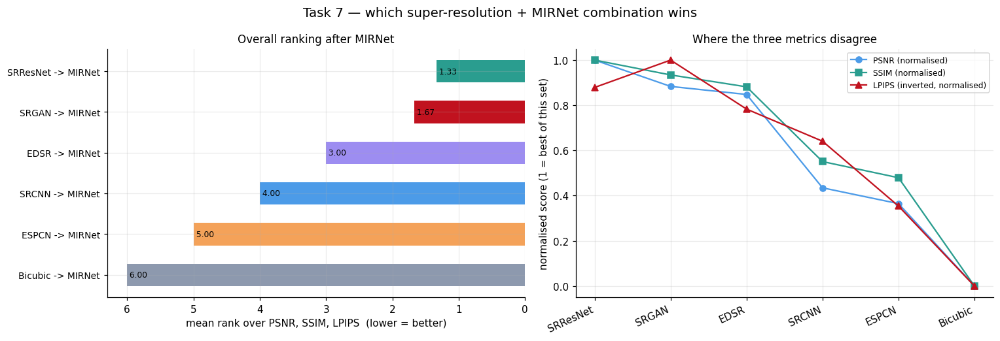

  saved -> outputs\figures\B_pipeline_cost.png


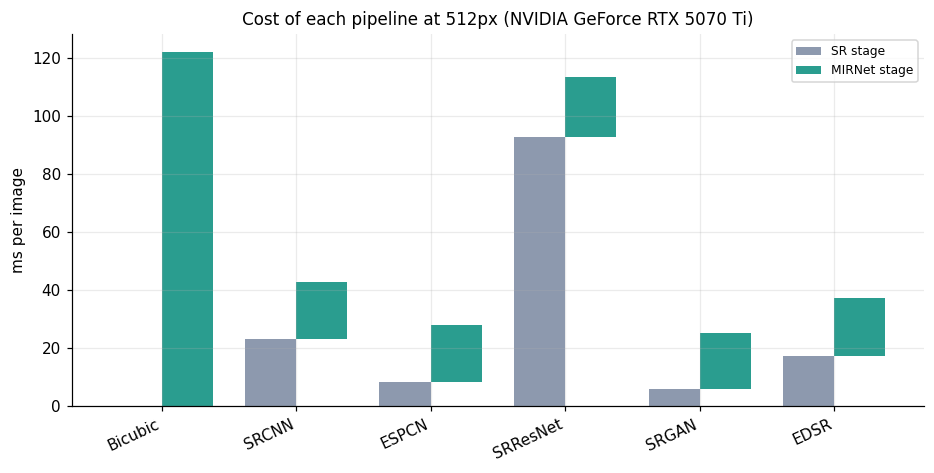

In [35]:
def plot_ranking():
    d = ranking.set_index("Pipeline")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    ax = axes[0]
    ys = np.arange(len(d))[::-1]
    ax.barh(ys, d.MeanRank, 0.55, color=[METHOD_COLORS[p.split(" ")[0]] for p in d.index])
    ax.set_yticks(ys); ax.set_yticklabels(d.index, fontsize=9)
    ax.invert_xaxis()
    ax.set_xlabel("mean rank over PSNR, SSIM, LPIPS  (lower = better)")
    ax.set_title("Overall ranking after MIRNet", fontsize=11)
    for y, v in zip(ys, d.MeanRank):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=8)

    ax = axes[1]
    xs = np.arange(len(d))
    norm = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-9)
    ax.plot(xs, norm(d.PSNR_after), "o-", label="PSNR (normalised)", color="#4c9be8")
    ax.plot(xs, norm(d.SSIM_after), "s-", label="SSIM (normalised)", color="#2a9d8f")
    ax.plot(xs, 1 - norm(d.LPIPS_after), "^-", label="LPIPS (inverted, normalised)",
            color="#c1121f")
    ax.set_xticks(xs); ax.set_xticklabels([p.split(" ")[0] for p in d.index],
                                          rotation=25, ha="right")
    ax.set_ylabel("normalised score (1 = best of this set)")
    ax.set_title("Where the three metrics disagree", fontsize=11)
    ax.legend(fontsize=8)
    fig.suptitle("Task 7 — which super-resolution + MIRNet combination wins", fontsize=13)
    plt.tight_layout()
    savefig(fig, "B_ranking")
    plt.show()


def plot_cost():
    fig, ax = plt.subplots(figsize=(8.6, 4.4))
    xs = np.arange(len(METHODS)); w = 0.38
    ax.bar(xs - w / 2, agg_div2k.Time_ms_before, w, label="SR stage", color="#8d99ae")
    ax.bar(xs + w / 2, agg_div2k.Time_ms_after - agg_div2k.Time_ms_before, w,
           bottom=agg_div2k.Time_ms_before, label="MIRNet stage", color="#2a9d8f")
    ax.set_xticks(xs); ax.set_xticklabels(METHODS, rotation=25, ha="right")
    ax.set_ylabel("ms per image")
    ax.set_title(f"Cost of each pipeline at {SCFG.max_eval_side}px "
                 f"({torch.cuda.get_device_name(0) if device.type=='cuda' else 'CPU'})",
                 fontsize=11)
    ax.legend(fontsize=8)
    plt.tight_layout()
    savefig(fig, "B_pipeline_cost")
    plt.show()


plot_ranking()
plot_cost()

In [36]:
# ------------------------------------------------------------------ one-page recap of everything
lines = ["=" * 78,
         "ASSIGNMENT 3 - RESULTS SUMMARY",
         "=" * 78,
         "",
         "PART A - CIFAR-10 convolution modules",
         "-" * 78,
         cls_summary[["Model", "Accuracy", "F1_macro", "Params", "MMACs",
                      "Train_total_s", "Latency_bs1_ms"]].to_string(index=False),
         "",
         f"best accuracy : {cls_summary.loc[cls_summary.Accuracy.idxmax(), 'Model']} "
         f"({cls_summary.Accuracy.max()*100:.2f}%)",
         f"cheapest      : {cls_summary.loc[cls_summary.Params.idxmin(), 'Model']} "
         f"({cls_summary.Params.min():,} parameters)",
         "",
         "PART B - MIRNet as a standalone restoration network (validation patches)",
         "-" * 78,
         standalone_wide[["Source", "PSNR_before", "PSNR_after", "dPSNR",
                          "LPIPS_before", "LPIPS_after", "dLPIPS"]].to_string(index=False),
         "",
         "PART B - super-resolution pipelines on DIV2K validation images",
         "-" * 78,
         agg_div2k[["Pipeline", "PSNR_before", "PSNR_after", "dPSNR",
                    "SSIM_after", "LPIPS_before", "LPIPS_after", "dLPIPS"]].to_string(index=False),
         "",
         "RANKING (1 = best)",
         "-" * 78,
         ranking[["Pipeline", "PSNR_after", "SSIM_after", "LPIPS_after", "MeanRank"]]
         .to_string(index=False),
         "",
         f"VERDICT: {verdict['best_pipeline_overall']} gives the best overall image quality "
         f"({verdict['best_pipeline_psnr_dB']:.2f} dB / SSIM {verdict['best_pipeline_ssim']:.4f} /"
         f" LPIPS {verdict['best_pipeline_lpips']:.4f}).",
         f"         Best perceptual quality: {verdict['best_perceptual_pipeline']}.",
         f"         MIRNet helps most after {verdict['largest_gain_from_mirnet']} "
         f"({verdict['largest_gain_dPSNR_dB']:+.2f} dB).",
         "=" * 78]
summary_text = "\n".join(lines)
(RESDIR / "SUMMARY.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)
print("\n  saved ->", RESDIR / "SUMMARY.txt")
print("\nfigures :", len(list(FIGDIR.glob('*.png'))), "PNGs in", FIGDIR)
print("tables  :", len(list(RESDIR.glob('*.csv'))), "CSVs in", RESDIR)

ASSIGNMENT 3 - RESULTS SUMMARY

PART A - CIFAR-10 convolution modules
------------------------------------------------------------------------------
   Model  Accuracy  F1_macro  Params  MMACs  Train_total_s  Latency_bs1_ms
Standard    0.9335    0.9334 3473994 494.82          250.7           1.372
  Atrous    0.9139    0.9138 3473994 494.82          250.7           1.494
      SK    0.9324    0.9324 5112266 722.31          461.0           3.361

best accuracy : Standard (93.35%)
cheapest      : Standard (3,473,994 parameters)

PART B - MIRNet as a standalone restoration network (validation patches)
------------------------------------------------------------------------------
   Source  PSNR_before  PSNR_after  dPSNR  LPIPS_before  LPIPS_after  dLPIPS
    SRCNN      28.7608     28.7088 -0.052        0.2953       0.2847 -0.0106
    ESPCN      28.1378     28.3696  0.232        0.3577       0.3285 -0.0292
 SRResNet      29.6194     29.4570 -0.162        0.2506       0.2504 -0.0002
    SRG